# APRAU 2026/27: Grupo 18
## Projeto de Machine Learning: Dataset Clínico Cardiometabólico

Sections:
1. Setup & Data Loading
2. Exploratory Data Analysis (EDA)
3. Regression  `target_regression`
4. Classification  `target_class`
5. Feature Selection (Ridge & Lasso)

## 1. Setup & Data Loading

In [1]:
# Run this cell only on Google Colab
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    DATASET_PATH = '../dataset_grupo_18.csv'

O notebook deteta automaticamente se está a correr no Colab ou localmente e define o caminho para o dataset.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_val_predict,
    LeaveOneOut, StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils import resample

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

Todas as bibliotecas necessárias são importadas num único bloco para facilitar a gestão de dependências. As principais são `pandas`/`numpy` para manipulação de dados, `matplotlib`/`seaborn` para visualização, `statsmodels` para o cálculo do VIF, e `sklearn` para modelos, métricas e pré-processamento.

---
## 2. Exploratory Data Analysis (EDA)

### 2.1 Data Loading

In [3]:
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Female,Overweight,Never,41,0.448276,26.039307,5.406343,287.000000,8.393934,176.000000,Moderate,No,Medium,No,No,126.000000,Medium,1.656905,5.747705,133.176000,89.793143,15.027543,8.477600,74.022857,64.889143,130.259429,Secondary,Employed,133.176000,9.42,1.111734,128.726611,97.0,N
1,Mature,Female,Normal,Current,47,0.517241,20.800000,6.945000,245.000000,9.800000,60.000000,High,No,Low,No,No,151.462687,Medium,7.000985,12.332504,123.000000,75.000000,8.300000,11.400000,88.000000,67.000000,118.000000,Secondary,Employed,123.000000,9.42,1.162052,129.057613,96.0,DI
2,Senior,Male,Normal,Former,76,0.850574,20.500000,5.362764,218.000000,6.300000,86.000000,Low,No,Low,No,No,149.402373,Medium,7.339123,12.304990,168.000000,79.000000,4.500000,8.700000,84.000000,59.000000,105.000000,Secondary,Unemployed,168.000000,9.42,1.424600,129.050057,169.0,N
3,Young,Female,Overweight,Never,20,0.206897,29.810000,4.800000,225.928571,7.000592,227.250000,High,Yes,High,Yes,Yes,150.785714,Low,7.628842,12.321293,133.642553,89.510638,15.708085,8.439149,73.553191,65.804255,133.378723,Primary,Unemployed,133.642553,9.42,1.063741,164.000000,90.0,N
4,Middle,Male,Overweight,Former,35,0.379310,27.320000,6.000000,225.071183,7.040413,148.762342,Low,No,Medium,No,Yes,147.833988,Low,7.414141,12.534473,134.235362,89.431688,15.107577,8.429047,74.042480,63.850746,130.987371,Secondary,Unemployed,134.235362,9.42,0.952215,130.545353,158.0,N


Foi feito o carregamento o dataset e inspecionamos as primeiras linhas para confirmar que o ficheiro foi lido corretamente: número de linhas/colunas esperado e tipos de dados visíveis.

### 2.2 Dataset Overview

In [4]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Data Types ===
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_level             object
low_hdl_cholesterol      object
high_ldl_cholesterol     object
blood_pressure          float64
sugar_consumption        object
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level          object
employment_status        object
systolic_index          float64
calcium_baseline     

Inspecionar os tipos de dados e a contagem de valores em falta é o primeiro diagnóstico de qualquer dataset. Confirma se colunas numéricas foram lidas como `object` e se é necessária imputação antes da modelação. Neste caso, o dataset **não possui valores em falta**.

In [5]:
# Separate feature types
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols   = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical:', categorical_cols)
print('Numerical:  ', numerical_cols)

Categorical: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']
Numerical:   ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']


Foi feito a separação das colunas em dois grupos: numéricas e categóricas. A análise exploratória e as visualizações diferem entre os dois tipos: histogramas e correlação de Pearson para numéricas; gráficos de barras e tabelas de frequência para categóricas.

=== target_class distribution ===
target_class
N     1450
DI     467
HT      83
Name: count, dtype: int64


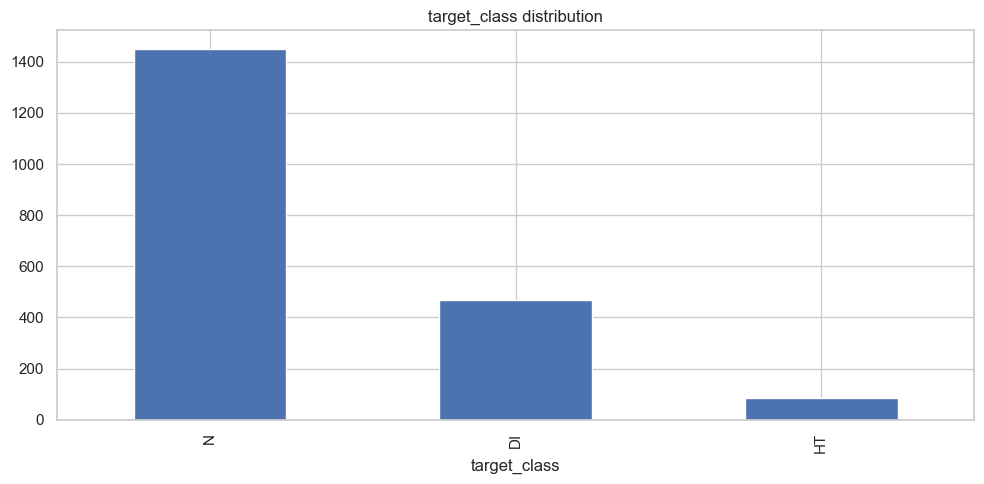

In [6]:
# Class balance
print('=== target_class distribution ===')
print(df['target_class'].value_counts())
df['target_class'].value_counts().plot(kind='bar', title='target_class distribution')
plt.tight_layout()
plt.show()

Verificar o equilíbrio de classes é crítico em classificação. Com desequilíbrio severo, um classificador pode atingir alta *accuracy* prevendo sempre a classe maioritária sem aprender nada útil. Isto obriga o uso de `StratifiedKFold` e métricas como F1 macro em vez de accuracy isolada.

### 2.3 Descriptive Statistics

In [7]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,22.182120,2.000000,29.000000,47.000000,65.000000,89.000000
age_normalized,2000.0,0.514695,0.254967,0.000000,0.310345,0.517241,0.724137,1.000000
bmi,2000.0,27.097259,6.675740,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,28.249128,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,64.646075,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,0.951538,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,0.935000,5.384979,12.287763,12.503725,12.691084,19.950612


Usamos `describe()` apenas sobre as colunas numéricas para evitar misturar métricas inaplicáveis: estatísticas como `mean` e `std` não fazem sentido para variáveis categóricas, e `unique`/`top`/`freq` não se aplicam a variáveis numéricas.

Estatísticas descritivas das features numéricas (média, desvio-padrão, quartis, mínimo e máximo). Procuramos features com desvio-padrão próximo de zero (possível variância constante), outliers onde o máximo está muito afastado do Q3, e médias em zonas de risco clínico.

### 2.4 Univariate Analysis

Histogramas de 30 bins para cada feature numérica revelam a forma da distribuição (normal, assimétrica, bimodal), outliers em caudas longas, features constantes (barra única) e padrões de imputação massiva (pico central dominante). Estas observações fundamentam as decisões de tratamento de dados na secção 2.6.

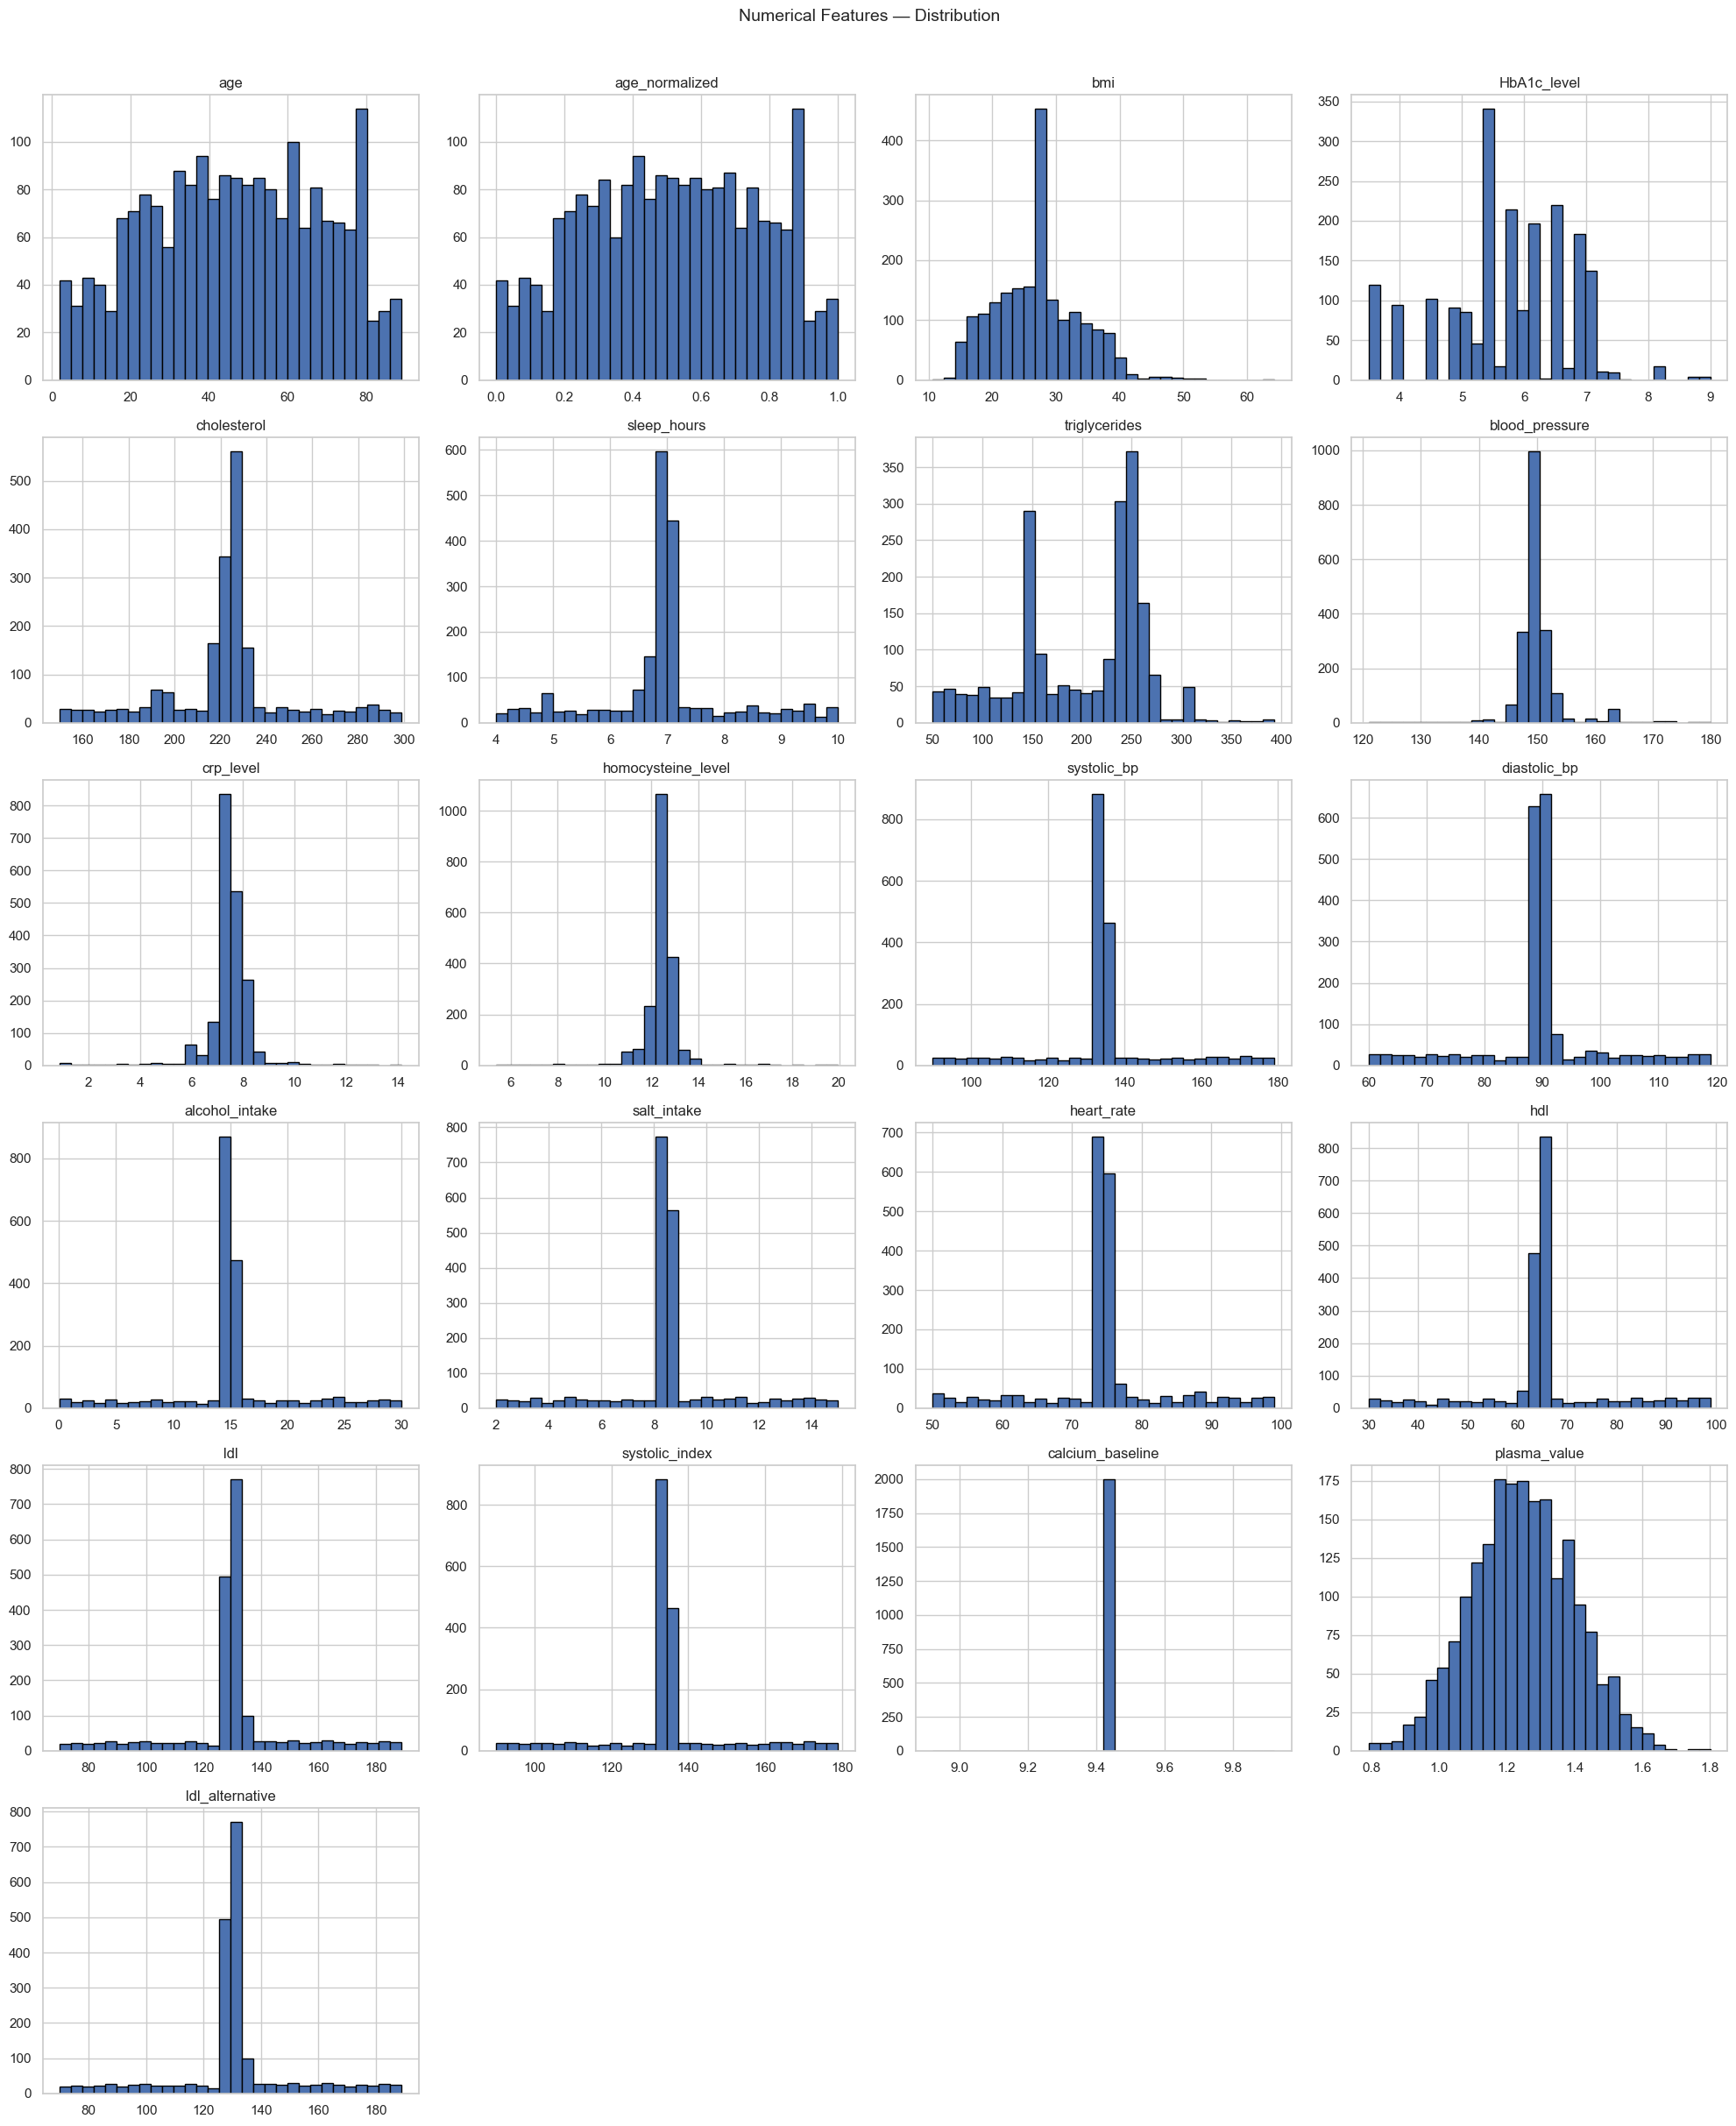

In [8]:
# Histograms for numerical features
num_features = [c for c in numerical_cols if c not in ['target_regression']]
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numerical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Features Numéricas

1. **Vários histogramas revelam padrões de imputação massiva.** As variáveis `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `systolic_index` e `ldl_alternative` apresentam todas o mesmo padrão: uma barra central dominante com caudas muito reduzidas. Isto indica que a maioria das observações tem valores calculados a partir de médias ou regras de imputação, e não medições diretas. Estas variáveis têm, por isso, baixo poder discriminante real para os modelos.

2. **Quatro variáveis bimodais sugerem heterogeneidade clínica real na população.** `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, evidenciando a existência de dois subgrupos populacionais com perfis de risco diferentes. Em `triglycerides`, os picos surgem a ~150 e ~230 mg/dL; em `crp_level` e `homocysteine_level`, um grupo com valores baixos (risco reduzido) e um grupo dominante com valores elevados (risco inflamatório/cardiovascular aumentado). Em `alcohol_intake`, os dois picos refletem dois padrões de consumo opostos. Esta bimodalidade pode ser informativa para a classificação.

3. **`calcium_baseline` tem variância zero e foi removida.** O histograma confirma visualmente o que as estatísticas descritivas já indicavam: uma única barra no valor 9.42 sem qualquer dispersão. Uma variável constante não transmite nenhuma informação ao modelo e foi, por isso, eliminada no passo de tratamento de dados.

4. **Três pares de variáveis redundantes foram identificados e um elemento de cada par foi removido.** Os histogramas de `age` e `age_normalized` têm exatamente a mesma forma (transformação linear), os de `ldl` e `ldl_alternative` são sobreponíveis, e os de `systolic_bp` e `systolic_index` são idênticos. A análise de correlação confirmou |r| = 1.00 em todos os casos, justificando a remoção de um elemento de cada par.

5. **`plasma_value` é a única feature com distribuição genuinamente normal e contínua.** O seu histograma apresenta uma curva em forma de seno centrada em ~1.2–1.3, sem picos artificiais nem concentrações anómalas. É provável que corresponda a uma medição laboratorial direta sem imputação significativa.

6. **`bmi` apresenta assimetria à direita com cauda longa.** A maioria dos valores concentra-se entre 20 e 35 kg/m², mas a cauda estende-se até ~64 kg/m², indicando casos de obesidade mórbida extrema. Estes outliers não foram removidos por serem clinicamente plausíveis, mas podem influenciar modelos sensíveis à escala.


Analisamos as features categóricas para identificar dominância extrema de uma categoria (que indicaria baixo poder discriminante) e para confirmar o número de classes distintas antes do encoding.

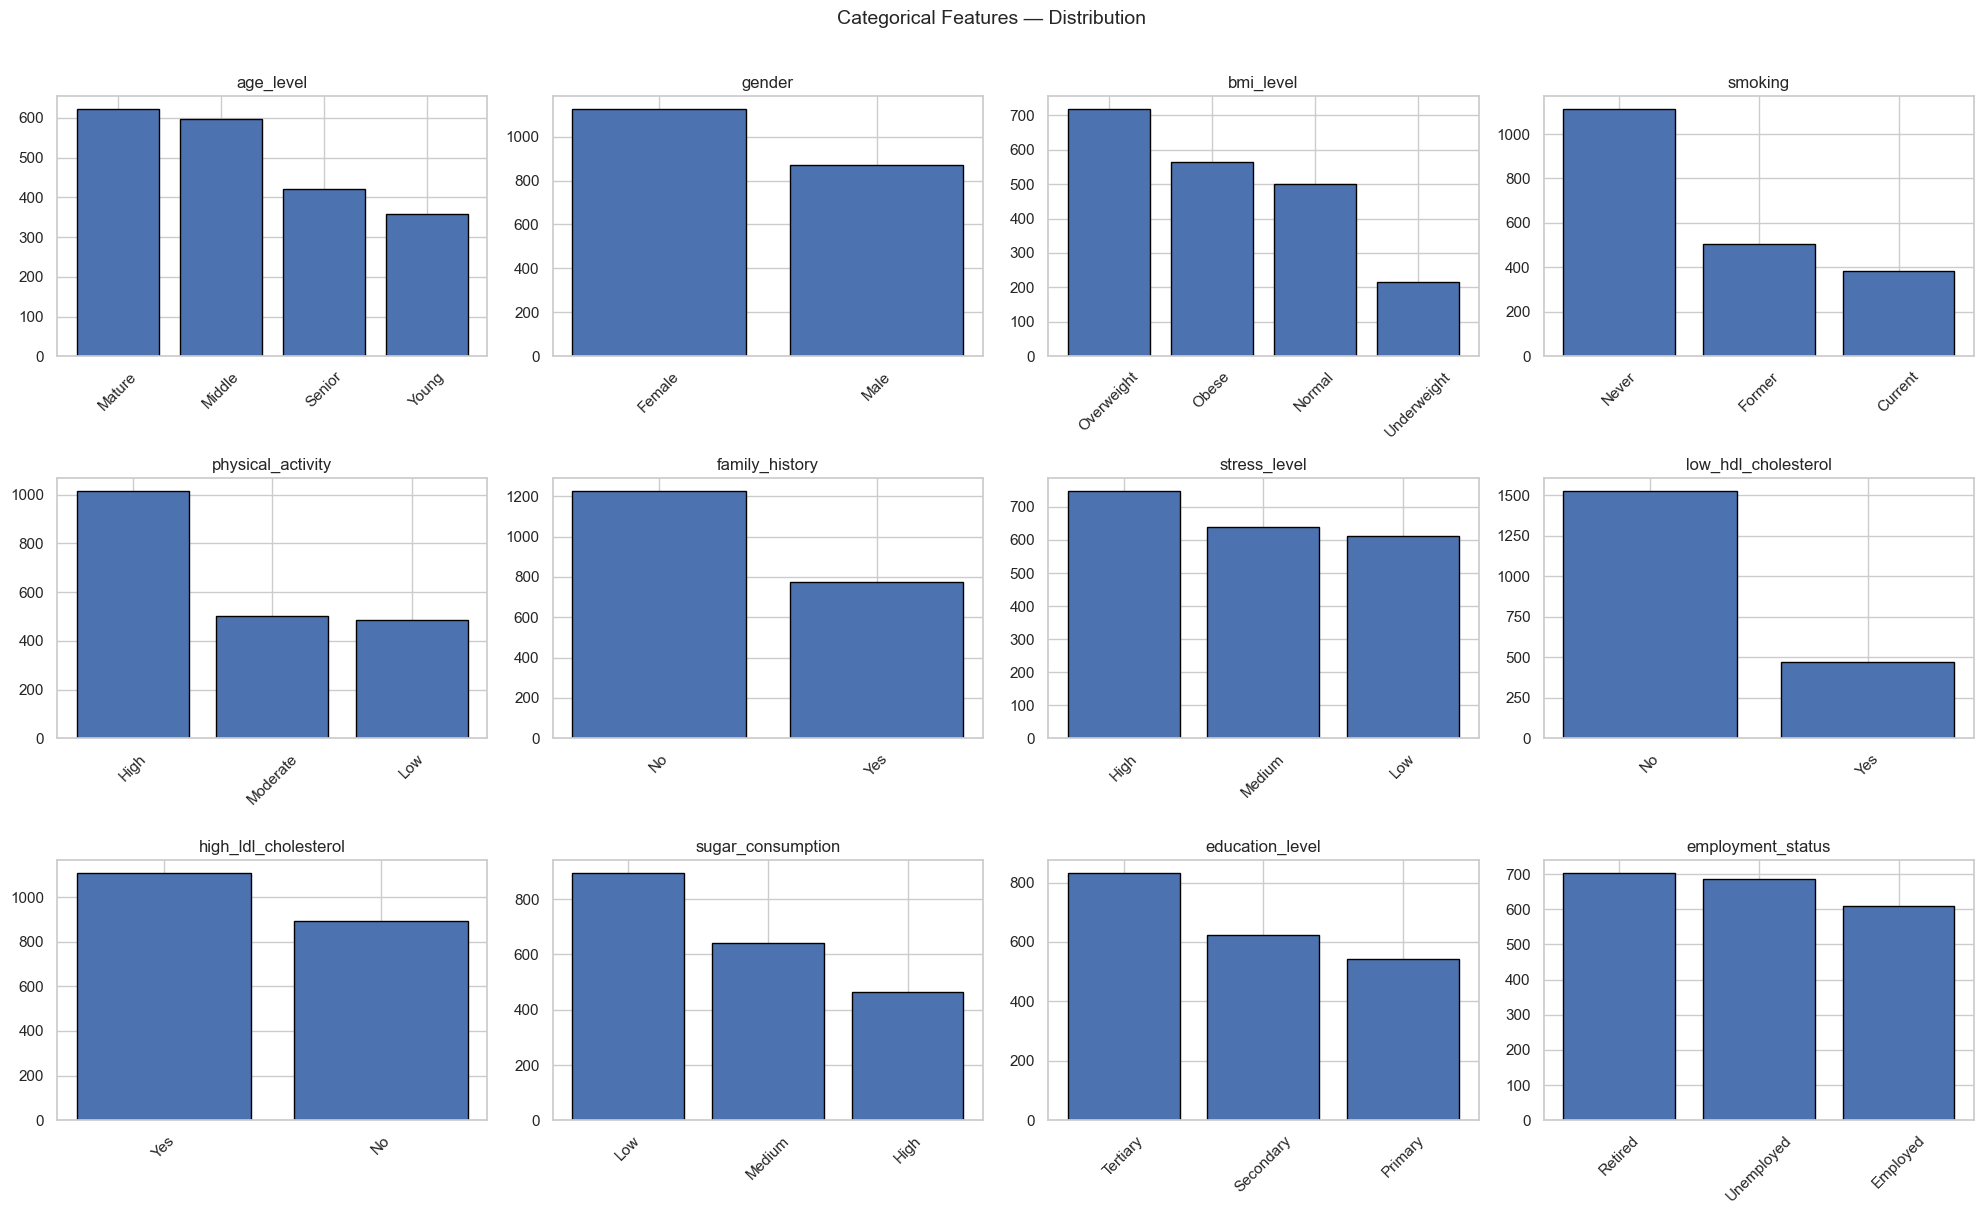

In [9]:
# Bar charts for categorical features
cat_features = [c for c in categorical_cols if c != 'target_class']
n = len(cat_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, edgecolor='black')
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Categorical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Features Categóricas

1. **Perfil clínico coerente com a população-alvo.** A predominância de `Mature` e `Senior` em `age_level`, combinada com `Overweight` e `Obese` em `bmi_level`, é consistente com um estudo de doenças cardiometabólicas. A exposição ao risco acumula-se com a idade e o excesso de peso é um fator de risco.

2. **Nenhuma categoria com dominância extrema.** Nenhuma feature tem uma classe com dominância extrema. Isto significa que todas as features têm pelo menos alguma variabilidade para o modelo aprender exceto `calcium_baseline` (que tem todos os seus values iguais), que irá ser removida.

3. **Paradoxo da atividade física.** `physical_activity` tem "High" como categoria mais frequente apesar do perfil de risco elevado da população. Isto pode refletir que a prática de atividade física é declarada (auto-reporte) e não necessariamente eficaz para mitigar outros fatores de risco. Esta feature pode ter baixo poder discriminante para `target_class` apesar da sua prevalência.

4. **`high_ldl_cholesterol` e `family_history` como potenciais preditores.** Ter LDL elevado  numa população maioritariamente saudável é clinicamente relevante: LDL elevado é um fator de risco independente. `family_history` é também substancial e difícil de controlar pelo indivíduo, tornando-a um marcador de risco estrutural.

5. **`employment_status`** apresenta uma distribuição praticamente uniforme entre as três categorias. Do ponto de vista de entropia de informação, esta é a feature mais equilibrada do conjunto, mas a sua ligação direta ao desenvolvimento de diabetes ou hipertensão é menos óbvia do que as restantes, cabendo a etapa de Feature Selection determinar se o seu contributo e real.

### 2.5 Bivariate Analysis

A matriz de correlação de Pearson deteta redundâncias. Pares com |r| ≈ 1.0 transportam a mesma informação e introduziriam multicolinearidade perfeita em modelos lineares. É também o ponto de partida para a análise VIF mais formal na secção de tratamento.

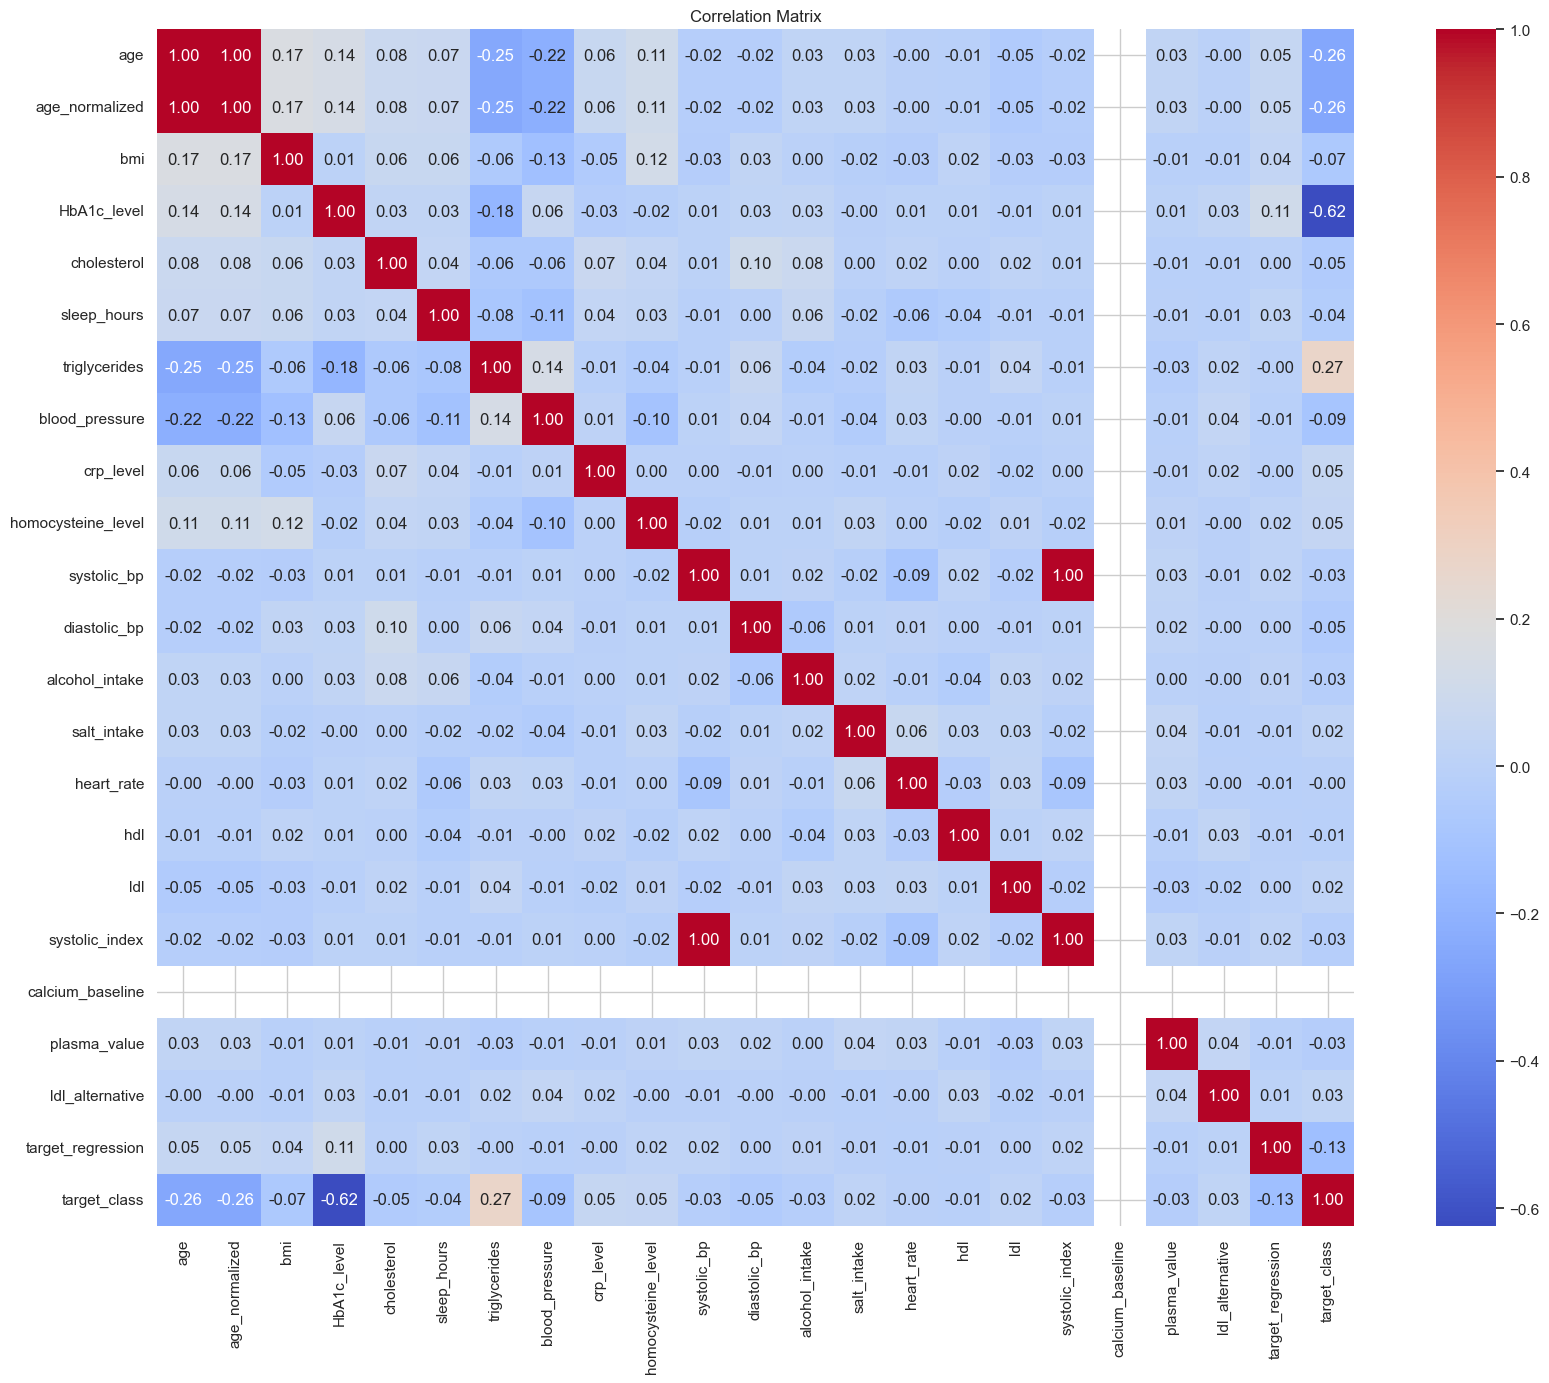

In [10]:
# Correlation heatmap: numerical features + target_class
_tc_map = {v: i for i, v in enumerate(sorted(df["target_class"].unique()))}
corr_df = df[numerical_cols].copy()
corr_df["target_class"] = df["target_class"].map(_tc_map)

corr = corr_df.corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


### Conclusões: Matriz de Correlação

1. **A maioria das correlações é muito fraca.** Quase todos os pares de features apresentam valores de |r| < 0.15, o que confirma que as variáveis numéricas são amplamente independentes entre si. Isto é esperado, dado que muitas delas resultam de imputação, o que atenua artificialmente as correlações.

2. **Dois pares de variáveis perfeitamente correlacionadas foram identificados.** Os blocos vermelho-escuros com r = 1.00 entre `age` e `age_normalized` e entre `systolic_bp` e `systolic_index` confirmam redundância total. Manter ambas as colunas num modelo introduziria multicolinearidade perfeita; um elemento de cada par foi removido no tratamento de dados.

3. **`calcium_baseline` aparece como linha e coluna em branco.** A ausência de qualquer cor reflete variância zero: uma feature constante tem correlação indefinida com qualquer outra variável. Foi removida por não conter informação discriminante.

4. **As correlações mais relevantes entre features envolvem `triglycerides` e `blood_pressure` com `age`.** São as únicas correlações moderadas visíveis: `triglycerides` com `age` (r = -0.25) e `blood_pressure` com `age` (r = -0.22). Ambas são negativas, sugerindo que valores mais baixos destas variáveis estão associados a idades mais avançadas.

5. **`target_class` (codificada como inteiro: DI=0, HT=1, N=2) mostra correlações fracas, mas interpretáveis, com as features numéricas.** As correlações mais expressivas são com `age` e `HbA1c_level`: valores mais elevados destas features associam-se a DI e HT (inteiros menores), resultando em correlações negativas. Nenhuma feature numérica individual apresenta |r| > 0.15 com `target_class`, confirmando que a separação entre classes não é capturada linearmente por features individuais e que os boxplots são necessários para visualizar a distribuição por classe.

Boxplots de cada feature numérica segmentados por `target_class` revelam o poder discriminante visual: classes com medianas e IQR distintos são boas candidatas a preditores. Permitem também identificar se outliers se concentram numa classe específica.

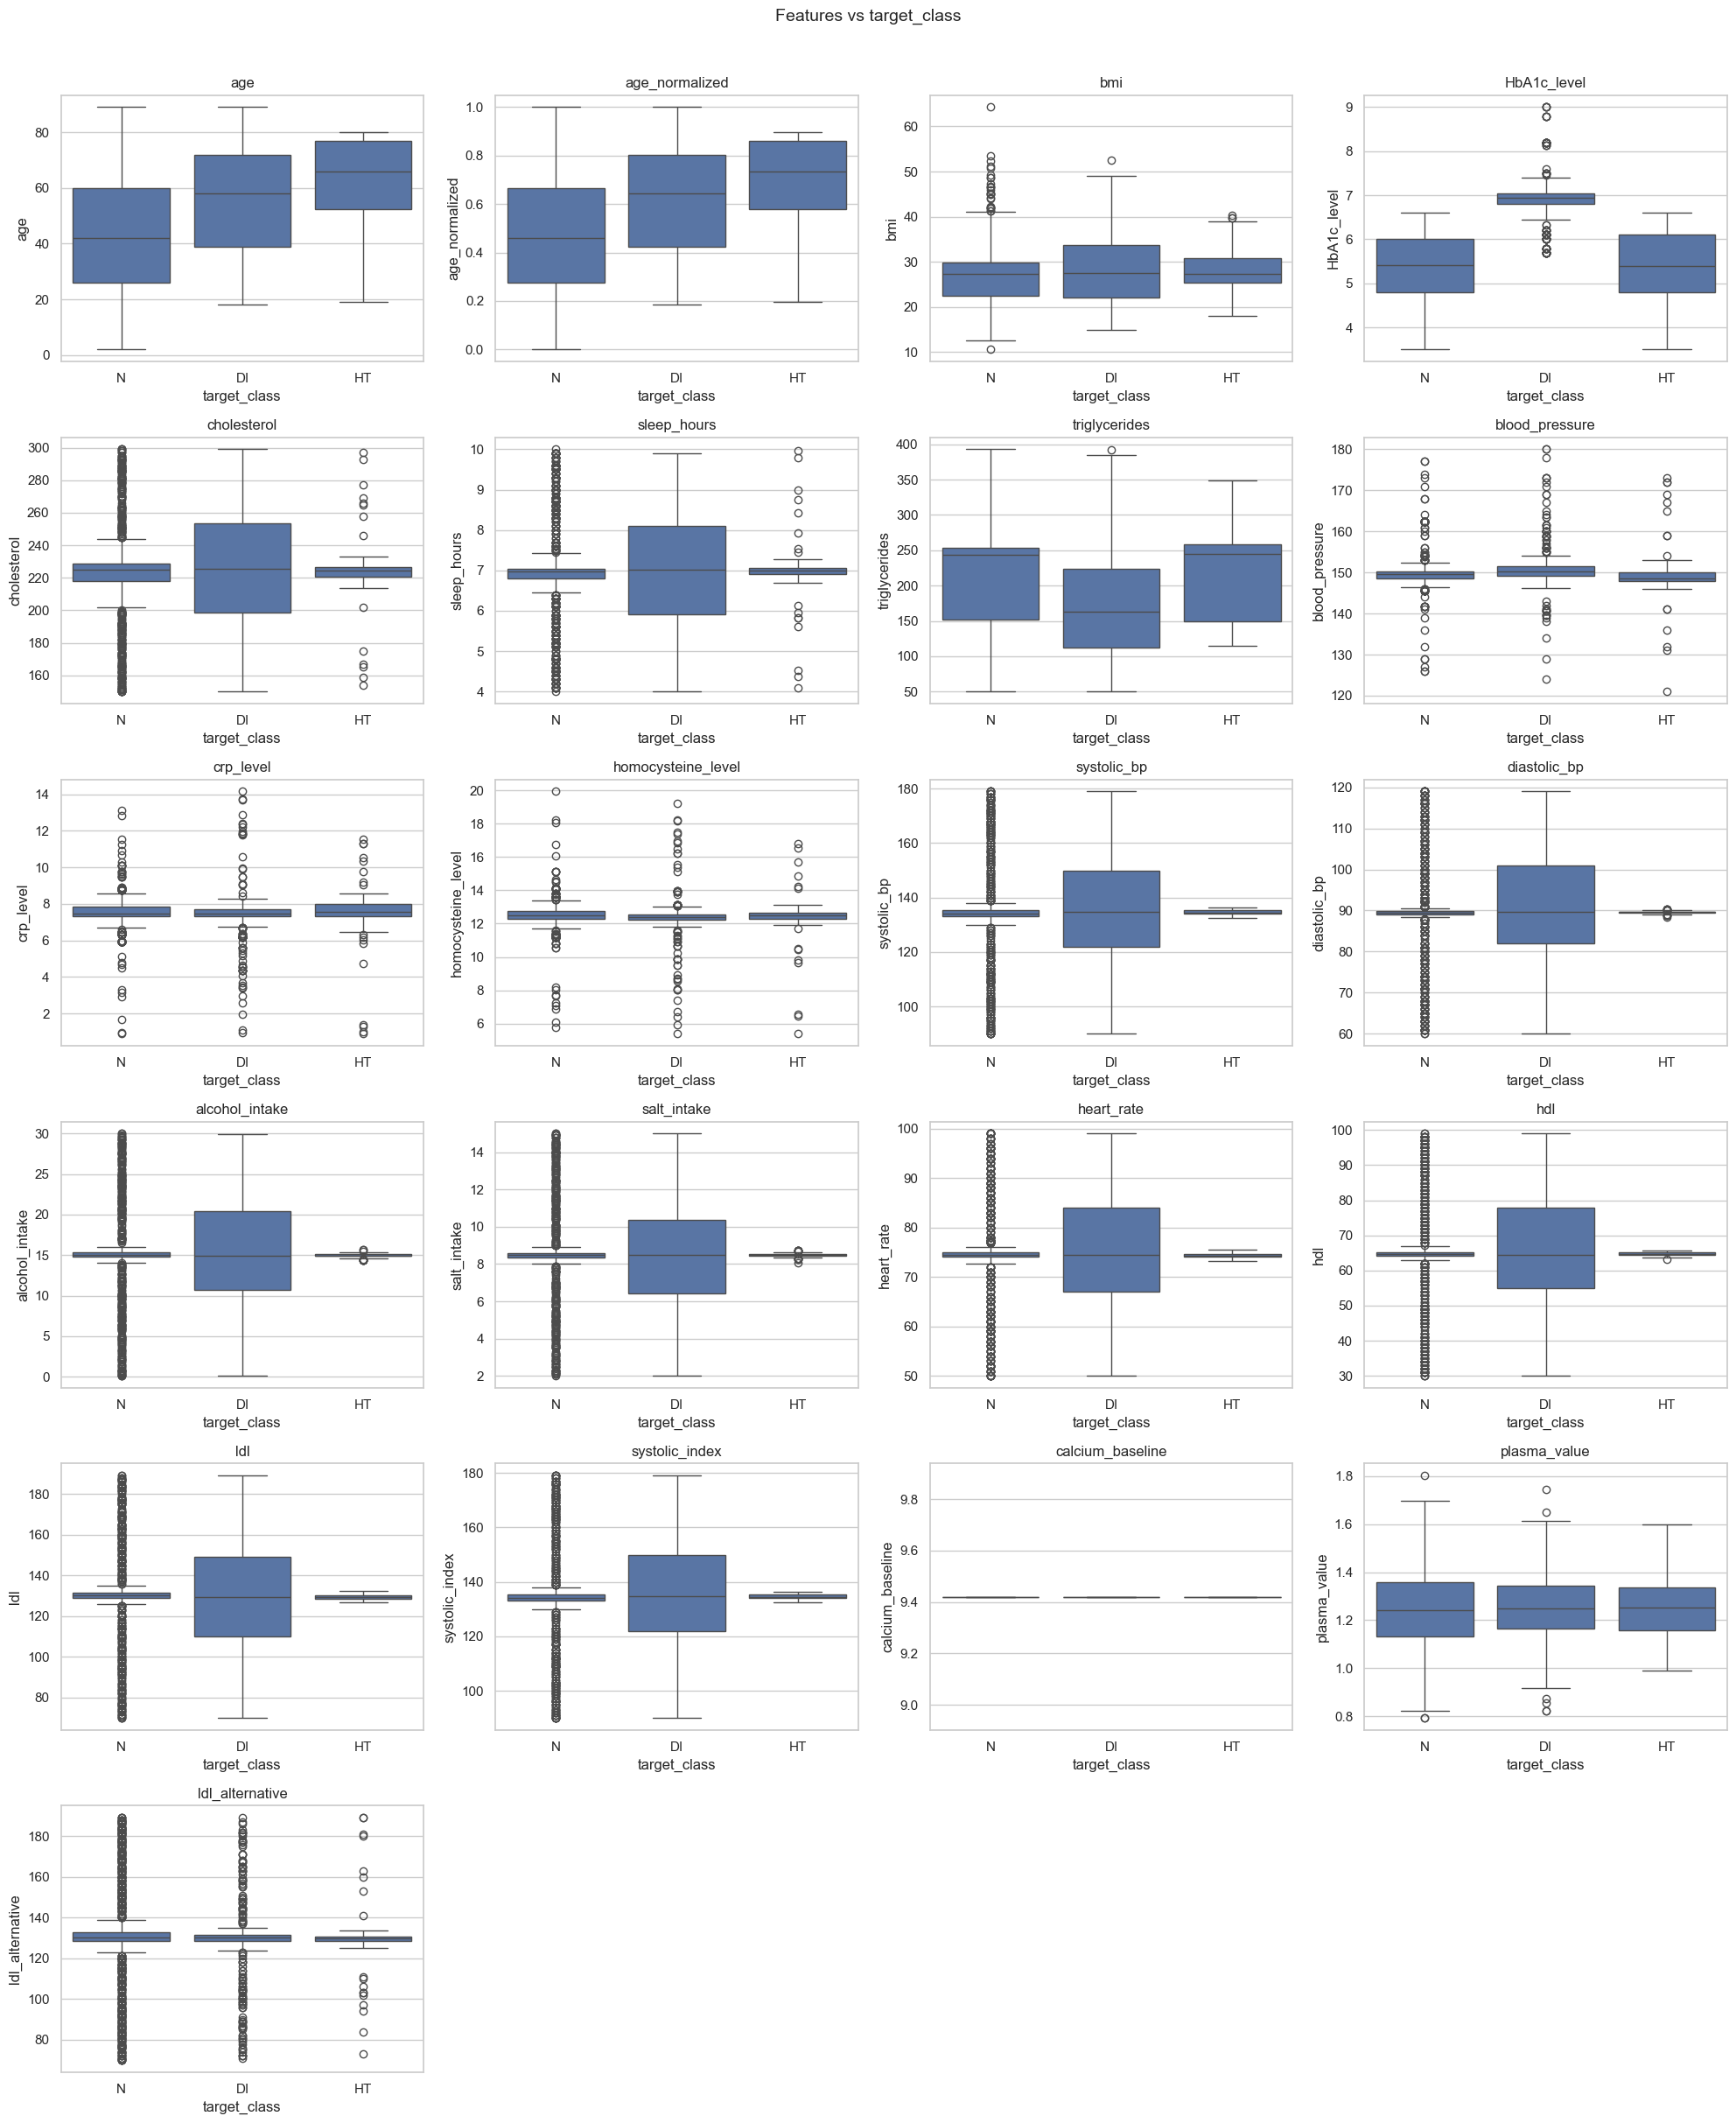

In [11]:
# Boxplots: numerical features vs target_class
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(x='target_class', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Features vs target_class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Conclusões: Boxplots Features vs `target_class`

Os boxplots complementam a matriz de correlação ao mostrar a **distribuição por classe** (medianas, IQR e outliers), em vez de um único coeficiente de correlação.

1. **`age` e `HbA1c_level` são os melhores discriminadores visuais.** Em `age`, a mediana aumenta claramente de N para DI e HT, com sobreposição reduzida entre as caixas. Em `HbA1c_level`, a classe DI tem mediana claramente superior face a N e HT, o que é clinicamente esperado: a hemoglobina glicada é o marcador de referência para a diabetes.

2. **`bmi` discrimina DI das restantes classes.** A classe DI apresenta mediana de IMC visivelmente superior a N e HT, consistente com a associação clínica entre obesidade e resistência à insulina. N e HT têm distribuições semelhantes entre si.

3. **A classe DI exibe sistematicamente caixas muito mais largas.** Em `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl` e `ldl_alternative`, N e HT apresentam IQR extremamente estreito (boxplot quase achatado), enquanto DI tem IQR amplo. Isto sugere que as classes N e HT têm maioritariamente valores imputados (variância artificialmente baixa), ao passo que DI contém mais medições reais.

4. **`cholesterol`, `sleep_hours`, `crp_level`, `homocysteine_level` e `plasma_value` não separam as classes.** As três caixas são praticamente sobreponíveis em mediana e amplitude, tornando estas variáveis pouco úteis para a classificação.

5. **`triglycerides` apresenta um padrão contraintuitivo.** A classe N tem mediana de triglicéridos mais alta do que DI, o que contradiz a expectativa clínica. Pode refletir a natureza sintética/imputada do dataset ou o facto de as classes DI e HT incluírem doentes já medicados (p. ex., com estatinas ou fibratos).

Foi feito o cálculo das correlações absolutas com `target_regression` para identificar os melhores preditores lineares. Como os modelos usados (Regressão Linear) também são lineares, a correlação de Pearson é um indicador adequado. Correlações muito fracas já antecipam dificuldade na tarefa de regressão.

Top correlations with target_regression:
HbA1c_level           0.106513
age_normalized        0.053761
age                   0.053761
bmi                   0.036418
sleep_hours           0.026823
systolic_index        0.018374
systolic_bp           0.018374
homocysteine_level    0.018204
alcohol_intake        0.014946
blood_pressure        0.011194
Name: target_regression, dtype: float64


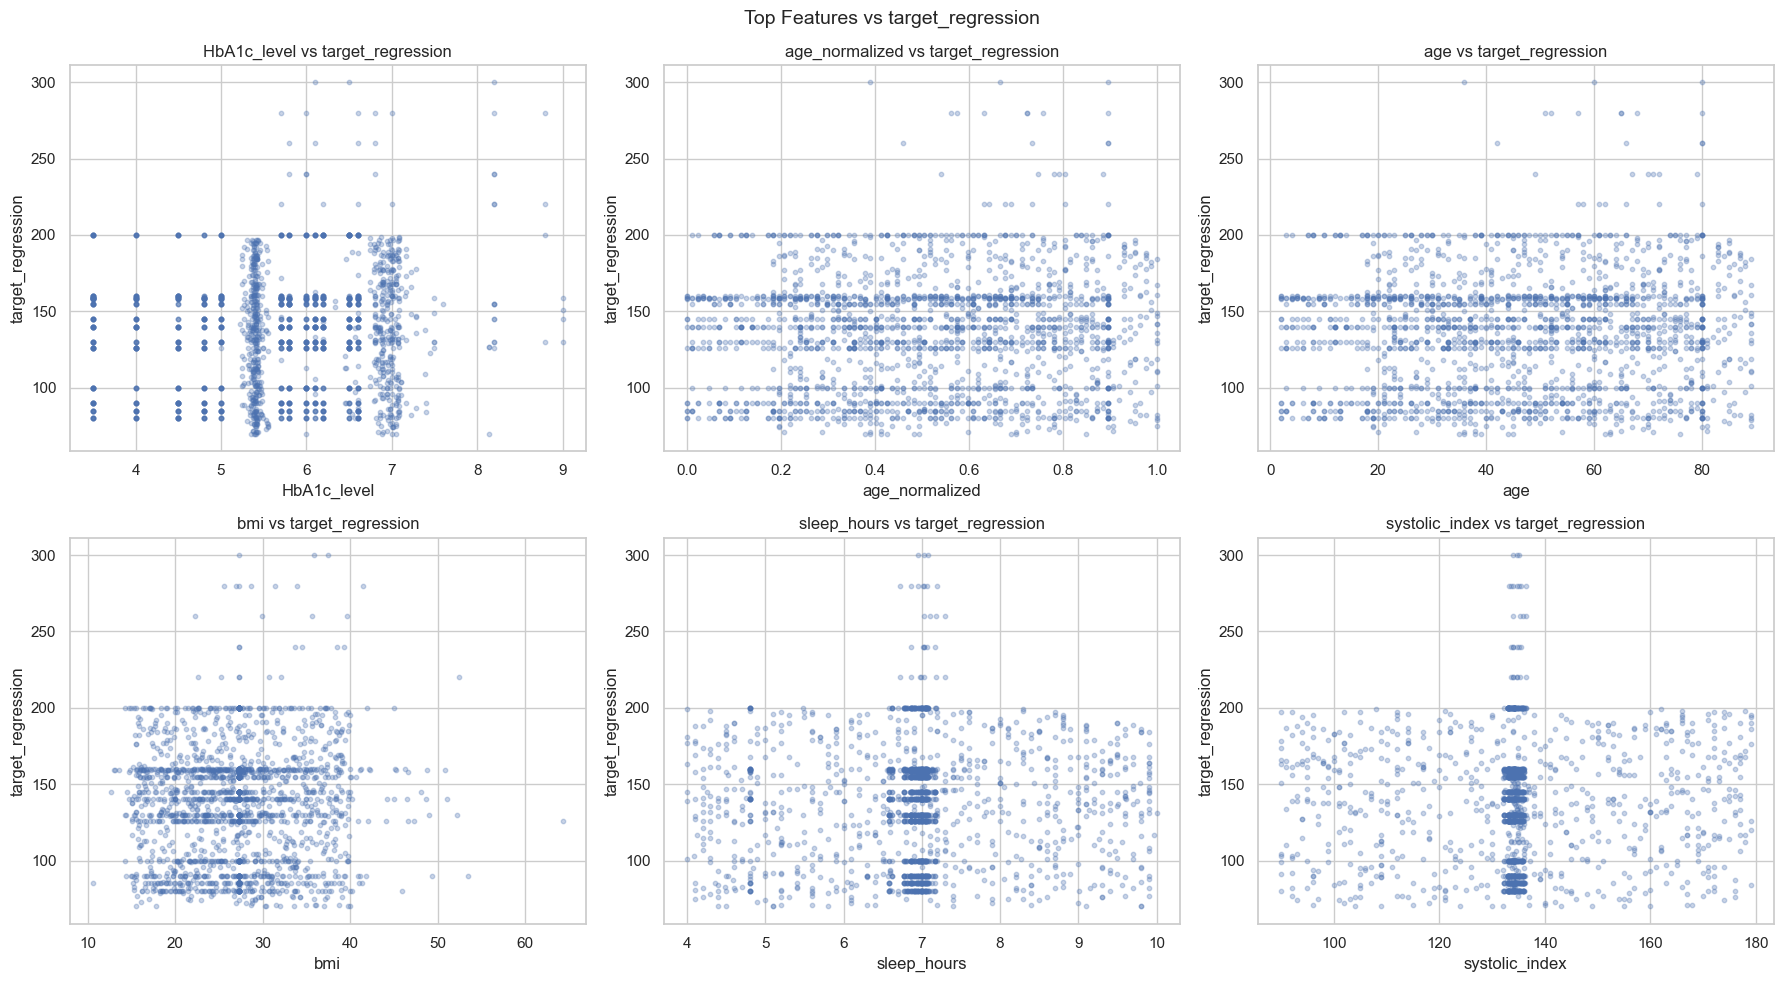

In [12]:
# Scatter: top correlated features vs target_regression
corr_with_target = df[numerical_cols].corr()['target_regression'].drop('target_regression').abs().sort_values(ascending=False)
print('Top correlations with target_regression:')
print(corr_with_target.head(10))

top_features = corr_with_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(top_features):
    axes[i].scatter(df[col], df['target_regression'], alpha=0.3, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_regression')
    axes[i].set_title(f'{col} vs target_regression')

plt.suptitle('Top Features vs target_regression', fontsize=14)
plt.tight_layout()
plt.show()

### Conclusões: Top Features vs `target_regression`

1. **Nenhuma feature tem relação linear expressiva com `target_regression`.** O valor máximo de correlação é |r| = 0.107 (`HbA1c_level`), muito abaixo do limiar convencional de correlação fraca (|r| = 0.3). Todos os scatter plots confirmam visualmente a ausência de tendência linear: os pontos distribuem-se em nuvens sem inclinação discernível.

2. **`HbA1c_level` é o melhor preditor, mas ainda insuficiente.** No seu scatter plot, observa-se que valores mais altos de HbA1c tendem ligeiramente a associar-se a valores mais altos de `target_regression`, mas a dispersão vertical é tão grande que essa tendência é quase invisível. O agrupamento em colunas verticais (valores discretos de HbA1c) reforça que muitas observações têm valores imputados por categoria clínica.

3. **`sleep_hours` e `systolic_bp` revelam imputação massiva nos scatter plots.** Ambos mostram uma concentração extrema de pontos numa banda vertical estreita, com `target_regression` a variar entre 70 e 300 nessa mesma banda, o que confirma que estas variáveis têm quase todos os valores imputados e, por isso, não explicam nada do alvo.

4. **`target_regression` apresenta valores semidiscretos.** Nos scatter plots são visíveis bandas horizontais em valores redondos (90, 100, 130, 140, 160, 200), sugerindo que o próprio alvo de regressão tem uma distribuição discreta ou foi arredondado, o que limita ainda mais a capacidade dos modelos lineares contínuos de o aproximar.

### 2.6 Data Treatment

Com base na EDA, identificamos três features a remover antes da modelação:
- **`calcium_baseline`**: variância zero (único valor 9.42), confirmado pelo histograma e `nunique() == 1`;
- **`systolic_index`**: duplicado exato de `systolic_bp` (r = 1.000 na matriz de correlação);
- **`age_normalized`**: transformação linear de `age` (r = 1.000), que introduziria multicolinearidade perfeita nos modelos lineares.

In [13]:
# --- 1. Constant features (nunique == 1 is more robust than std == 0) ---
constant_cols = [c for c in numerical_cols if df[c].nunique() == 1]
print('Constant features (zero variance):', constant_cols)

# --- 2. Redundant features ---
# 2a. Exact duplicates (bit-for-bit identical columns)
redundant_cols = set()
num_list = list(numerical_cols)
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and df[num_list[i]].equals(df[num_list[j]]):
            redundant_cols.add(num_list[j])
            print(f'  DUPLICATE : "{num_list[i]}" == "{num_list[j]}"  →  dropping "{num_list[j]}"')

# 2b. Perfect linear correlation (|r| >= 0.9999 catches derived/scaled columns)
corr_matrix = df[num_list].corr().abs()
for i in range(len(num_list)):
    for j in range(i + 1, len(num_list)):
        if num_list[j] not in redundant_cols and corr_matrix.iloc[i, j] >= 0.9999:
            redundant_cols.add(num_list[j])
            print(f'  CORR≈1.0  : "{num_list[i]}" ↔ "{num_list[j]}" (r={corr_matrix.iloc[i, j]:.8f})  →  dropping "{num_list[j]}"')

print('\nColumns to remove:', sorted(constant_cols + list(redundant_cols)))

Constant features (zero variance): ['calcium_baseline']
  DUPLICATE : "systolic_bp" == "systolic_index"  →  dropping "systolic_index"
  CORR≈1.0  : "age" ↔ "age_normalized" (r=1.00000000)  →  dropping "age_normalized"

Columns to remove: ['age_normalized', 'calcium_baseline', 'systolic_index']


Separar a deteção da aplicação permite rever a lista antes de eliminar as colunas. O resultado limpo é guardado em `df_clean`.

In [14]:
# --- 3. Apply treatment ---
cols_to_drop = list(set(constant_cols) | redundant_cols)
print('Columns to drop:', sorted(cols_to_drop))

df_clean = df.drop(columns=cols_to_drop)
print(f'\nOriginal shape : {df.shape}')
print(f'Cleaned shape  : {df_clean.shape}')

Columns to drop: ['age_normalized', 'calcium_baseline', 'systolic_index']

Original shape : (2000, 35)
Cleaned shape  : (2000, 32)


Persistimos o dataset limpo em disco para garantir reprodutibilidade e facilitar inspeção manual ou uso noutros contextos.

In [15]:
# Save cleaned dataset for external use
CLEANED_PATH = DATASET_PATH.replace('dataset_grupo_18.csv', 'dataset_grupo_18_cleaned.csv')
df_clean.to_csv(CLEANED_PATH, index=False)
print(f'Cleaned dataset saved to {CLEANED_PATH}')
print(f'Final shape: {df_clean.shape}')
print(f'Remaining features: {df_clean.columns.tolist()}')

Cleaned dataset saved to ../dataset_grupo_18_cleaned.csv
Final shape: (2000, 32)
Remaining features: ['age_level', 'gender', 'bmi_level', 'smoking', 'age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class']


Estatísticas descritivas do dataset após tratamento confirmam que as features removidas já não estão presentes e que as distribuições das sobreviventes são as esperadas.

In [16]:
df_clean.select_dtypes(include=[np.number]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,46.778500,22.182120,2.000000,29.000000,47.000000,65.000000,89.000000
bmi,2000.0,27.097259,6.675740,10.590000,22.430000,27.320000,30.971278,64.270000
HbA1c_level,2000.0,5.712300,1.033372,3.500000,5.245652,5.700000,6.500000,9.000000
cholesterol,2000.0,223.494228,28.249128,150.000000,217.232323,225.000000,229.631579,299.000000
sleep_hours,2000.0,6.930174,1.154802,4.000000,6.770819,6.968389,7.080402,10.000000
triglycerides,2000.0,201.077147,64.646075,50.000000,149.733553,228.500000,251.281250,393.000000
blood_pressure,2000.0,150.123830,4.221680,121.000000,148.680000,149.713320,150.720942,180.000000
crp_level,2000.0,7.502463,0.951538,0.900569,7.312963,7.462859,7.824534,14.156036
homocysteine_level,2000.0,12.443702,0.935000,5.384979,12.287763,12.503725,12.691084,19.950612
systolic_bp,2000.0,134.460825,15.782950,90.000000,133.052402,134.167413,135.590248,179.000000


### Conclusões: Data Treatment

O pipeline de tratamento de dados removeu **3 das 22 features numéricas originais**, reduzindo o dataset de (2000 × 35) para (2000 × 32):

| Passo | Features removidas | Critério | Evidência da EDA |
|---|---|---|---|
| Variância zero | `calcium_baseline` | nunique == 1 | Histograma com barra única em 9.42 |
| Redundância exata | `systolic_index` | r = 1.000 com `systolic_bp` | Matriz de correlação + boxplots idênticos |
| Correlação perfeita | `age_normalized` | r = 1.000 com `age` | Bloco vermelho escuro na matriz de correlação |

**Dataset limpo (2000 × 32):** mantém todas as features numéricas com variabilidade real, incluindo `age`, `bmi`, `HbA1c_level`, `cholesterol`, `triglycerides`, `alcohol_intake`, entre outras. As features com padrões de imputação massiva (spike nos histogramas) permanecem (o seu impacto nos modelos será avaliado na etapa de Feature Selection).

## 2.7. Conclusões da EDA

### 2.7.1 Estatísticas Descritivas

As estatísticas descritivas (calculadas apenas sobre features numéricas, para evitar NaN de métricas inaplicáveis a categóricas) revelam uma população com perfil de risco cardiometabólico elevado:

| Observação | Valor | Interpretação clínica |
|---|---|---|
| `cholesterol` médio | 223.5 mg/dL | Acima do limiar borderline (≥ 200) |
| `triglycerides` médio | 201.1 mg/dL | Limiar de risco moderado (≥ 150) |
| `crp_level` médio | 7.5 | Inflamação vascular elevada (> 3) |
| `homocysteine_level` médio | 12.4 µmol/L | Risco cardiovascular (> 10) |
| `bmi` máximo | 64.3 kg/m² | Obesidade mórbida extrema — cauda longa à direita |
| `blood_pressure` std | 4.22 para amplitude 59 | Desvio-padrão anormalmente baixo — medida derivada/imputada |
| `calcium_baseline` | sempre 9.42 | **Variância zero** — sem informação discriminante, removida |

---

### 2.7.2 Análise Univariada

**Numérica**
**Padrões principais:**
- **Imputação massiva**: `cholesterol`, `blood_pressure`, `systolic_bp`, `diastolic_bp`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `ldl_alternative` apresentam uma barra central dominante com caudas muito reduzidas, indicando que a maioria dos valores foi imputada por médias populacionais.
- **Bimodal**: `triglycerides`, `crp_level`, `homocysteine_level` e `alcohol_intake` apresentam dois picos distintos, sugerindo dois subgrupos populacionais com perfis de risco diferentes.
- **`plasma_value`**: única feature com distribuição genuinamente normal e contínua.
- **`bmi`**: assimétrica à direita com cauda até 64.3 kg/m².
- **`calcium_baseline`**: barra única em 9.42 → variância zero → removida.

**Categóricas** 
**Desequilíbrio crítico de `target_class`:**

```
N  → 1450  (72.5%)   ← classe maioritária
DI →  467  (23.4%)
HT →   83  ( 4.1%)   ← classe minoritária severa
```

> Um classificador que preveja sempre *N* obtém **72.5% de accuracy** sem aprender nada. Métricas de avaliação devem incluir **F1 macro** e **recall por classe**, não apenas accuracy. `StratifiedKFold` é obrigatório para preservar as proporções em todos os folds.

---

### 2.7.3 Análise Bivariada

**Matriz de correlacao (inclui `target_class`):**
Pares redundantes confirmados: `systolic_bp`/`systolic_index` (r = 1.000) e `age`/`age_normalized` (r = 1.000). Restantes correlacoes entre features: |r| < 0.15 (imputacao massiva atenua as correlacoes). `target_class` (DI=0, HT=1, N=2) mostra correlacoes negativas com `age` e `HbA1c_level`: valores mais elevados associam-se ao estado saudavel (N=2), confirmando os boxplots. Nenhuma feature numerica apresenta |r| > 0.15 com `target_class`.

**Boxplots vs `target_class`:**
- `age` e `HbA1c_level` são os melhores discriminadores visuais: medianas distintas entre N, DI e HT.
- `bmi` discrimina DI das restantes classes.
- A classe DI apresenta IQR sistematicamente mais largo do que N e HT em múltiplas features, revelando maior presença de medições reais (vs. imputadas).

**Correlações com `target_regression` todas fracas:**

| Feature | \|r\| |
|---|---|
| `HbA1c_level` | **0.107** ← melhor predictor |
| `age` | 0.054 |
| `bmi` | 0.036 |
| `sleep_hours` | 0.027 |
| `systolic_bp` | 0.018 |
| `homocysteine_level` | 0.018 |
| `alcohol_intake` | 0.015 |

> O limiar convencional de correlação fraca é |r| = 0.3. **Nenhuma feature sequer o atinge.** Os scatter plots confirmam ausência de tendências lineares claras e revelam que `target_regression` tem valores semi-discretos (bandas horizontais em valores redondos), o que limita ainda mais os modelos lineares. Os R² baixos são uma propriedade do dataset, não uma falha metodológica.

---

### 2.7.4 Tratamento de Dados

**Remoção de features não informativas/redundantes (35 → 32 colunas):**

| Feature removida | Motivo |
|---|---|
| `calcium_baseline` | Variância zero (valor único = 9.42) — zero poder discriminante |
| `systolic_index` | Duplicado exato de `systolic_bp` (r = 1.000) |
| `age_normalized` | Transformação linear de `age` (r = 1.000) — preferível manter a escala original |

**Valores em falta:** nenhum encontrado: nem NaN reais nem strings NaN ocultas nas categóricas. Dataset completamente preenchido.

---

### 2.7.5 Dataset Final

O dataset exportado (`dataset_grupo_18_cleaned.csv`) tem **2000 × 32**:

| Tipo | Features |
|---|---|
| **Categóricas (12)** | `age_level`, `gender`, `bmi_level`, `smoking`, `physical_activity`, `family_history`, `stress_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol`, `sugar_consumption`, `education_level`, `employment_status` |
| **Numéricas (18)** | `age`, `bmi`, `HbA1c_level`, `cholesterol`, `sleep_hours`, `triglycerides`, `blood_pressure`, `crp_level`, `homocysteine_level`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`, `plasma_value`, `ldl_alternative` |
| **Alvos (2)** | `target_regression`, `target_class` |

**Implicações para os passos seguintes:**
1. **Regressão**: correlações lineares com `target_regression` são todas fracas (max |r| = 0.107) e o alvo é semi-discreto → esperar R² baixos nos modelos lineares.
2. **Classificação**: desequilíbrio severo (72.5% / 23.4% / 4.1%) → usar `StratifiedKFold` + F1 macro como métrica principal.
3. **Feature selection**: presença de features com imputação massiva que irão ser resolvidas na etapa 5, onde L1, L2 e Elastic Net deverão atribuir-lhes coeficientes baixos por não discriminarem as classes/alvo.

---
## Shared Preprocessing

Encode `df_clean` once for all supervised learning tasks.

Antes das secções de Classificação e Feature Selection, codificamos as features categóricas com `pd.get_dummies(drop_first=True)`, que cria colunas binárias sem assumir ordem entre categorias (ao contrário do `LabelEncoder`). O `target_class` é codificado separadamente com `LabelEncoder` para compatibilidade com os classificadores sklearn. O `StandardScaler` (ajustado em todos os dados) é mantido para exploração e feature selection por CV; na avaliação holdout da classificação deve ser ajustado apenas no treino.

In [17]:
_cat_feature_cols = [
    col for col in df_clean.select_dtypes(include='object').columns
    if col not in ['target_regression', 'target_class']
]
df_enc = pd.get_dummies(df_clean, columns=_cat_feature_cols,
                        drop_first=True, dtype=int)

# Encode target_class as integers for sklearn classifiers
df_enc['target_class'] = LabelEncoder().fit_transform(
    df_clean['target_class'].astype(str)
)

# Feature list (excludes both targets)
FEATURES = [c for c in df_enc.columns
            if c not in ['target_regression', 'target_class']]
feature_names = np.array(FEATURES)

print(f'Features ({len(FEATURES)}): {FEATURES}')
print('Class distribution:', df_enc['target_class'].value_counts().to_dict())


Features (40): ['age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'plasma_value', 'ldl_alternative', 'age_level_Middle', 'age_level_Senior', 'age_level_Young', 'gender_Male', 'bmi_level_Obese', 'bmi_level_Overweight', 'bmi_level_Underweight', 'smoking_Former', 'smoking_Never', 'physical_activity_Low', 'physical_activity_Moderate', 'family_history_Yes', 'stress_level_Low', 'stress_level_Medium', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'sugar_consumption_Low', 'sugar_consumption_Medium', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Retired', 'employment_status_Unemployed']
Class distribution: {2: 1450, 0: 467, 1: 83}


---
## 3. Regression — Predicting `target_regression`

Define o alvo de regressão, cria a matriz de features como DataFrame (para seleção por nome de coluna) e divide em treino/teste com proporção 80/20. O `StandardScaler` é ajustado exclusivamente no conjunto de treino (`fit_transform`) e aplicado por transformação ao conjunto de teste (`transform`), evitando que estatísticas do teste influenciem a normalização. Para a Regressão Linear Ordinária, a escala não afeta o R2 nem o RMSE, mas garante consistência com o pipeline de validação cruzada.

In [18]:
y_reg = df_enc['target_regression'].values
X_reg = df_enc[FEATURES]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

# Fit scaler on training data only to avoid leakage
scaler_r = StandardScaler()
X_train_r_scaled = pd.DataFrame(
    scaler_r.fit_transform(X_train_r),
    columns=X_train_r.columns,
    index=X_train_r.index
)
X_test_r_scaled = pd.DataFrame(
    scaler_r.transform(X_test_r),
    columns=X_test_r.columns,
    index=X_test_r.index
)

print(f'Train: {X_train_r_scaled.shape} | Test: {X_test_r_scaled.shape}')


Train: (1600, 40) | Test: (400, 40)


`evaluate_reg` centraliza o cálculo das três métricas para garantir consistência entre modelos:
- **R²**: proporção da variância explicada; 0 equivale a prever a média, negativo é pior do que a média;
- **MAE**: erro médio absoluto, na mesma unidade que o alvo, robusto a outliers;
- **RMSE**: penaliza mais os erros grandes, útil quando esses erros são mais prejudiciais.

In [19]:
def evaluate_reg(name, y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'[{name}]  R²={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}')
    return {'Model': name, 'R²': r2, 'MAE': mae, 'RMSE': rmse}

### 3.1 Simple Linear Regression

Treinou-se uma Regressão Linear Simples para cada feature individualmente e ordenam-se os resultados por **R² médio em validação cruzada (5-fold) calculado exclusivamente no conjunto de treino**. Usar o conjunto de teste para este ranking introduziria data leakage: o modelo final seria avaliado no mesmo conjunto que influenciou a seleção de features.

In [20]:
# Rank features by mean 5-fold CV R² on training data only.
# Using the test set here would contaminate feature selection.
reg_results_simple = []
for feat in FEATURES:
    m = LinearRegression()
    cv_r2 = cross_val_score(m, X_train_r_scaled[[feat]], y_train_r,
                            cv=5, scoring='r2')
    reg_results_simple.append({'Feature': feat, 'R² (CV)': np.mean(cv_r2)})

results_simple_df = pd.DataFrame(reg_results_simple).sort_values('R² (CV)', ascending=False)
results_simple_df.head(10)


,Feature,R² (CV)
2,HbA1c_level,0.006011
0,age,-0.000337
20,age_level_Young,-0.002802
4,sleep_hours,-0.002832
19,age_level_Senior,-0.003145
37,education_level_Tertiary,-0.003248
35,sugar_consumption_Medium,-0.003269
9,systolic_bp,-0.003350
1,bmi,-0.003738
38,employment_status_Retired,-0.003788


Treinou-se o modelo final com a melhor feature e visualizamos a relação entre os valores reais e preditos. O scatter plot permite confirmar se a relação é genuinamente linear ou se há padrões (heterocedasticidade, tendência residual) que o modelo linear não consegue capturar.

Best single feature: HbA1c_level
[Simple LR]  R²=0.0083  MAE=30.8520  RMSE=38.3962


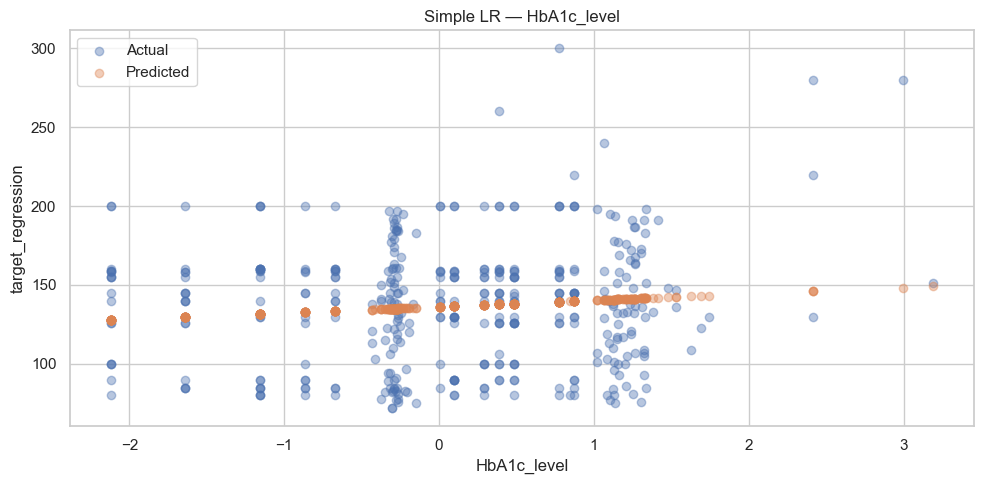

In [21]:
best_feat = results_simple_df.iloc[0]['Feature']
print(f'Best single feature: {best_feat}')

model_slr = LinearRegression()
model_slr.fit(X_train_r_scaled[[best_feat]], y_train_r)
y_pred_slr = model_slr.predict(X_test_r_scaled[[best_feat]])
reg_metrics = [evaluate_reg('Simple LR', y_test_r, y_pred_slr)]

plt.scatter(X_test_r_scaled[best_feat], y_test_r, alpha=0.4, label='Actual')
plt.scatter(X_test_r_scaled[best_feat], y_pred_slr, alpha=0.4, label='Predicted')
plt.xlabel(best_feat)
plt.ylabel('target_regression')
plt.legend()
plt.title(f'Simple LR — {best_feat}')
plt.tight_layout()
plt.show()

O gráfico mostra claramente que o modelo não consegue fazer previsões úteis com apenas esta feature. Os pontos cor de laranja (valores previstos) estão quase todos alinhados na horizontal, à volta de 130-140 — o modelo está basicamente a prever o mesmo valor para toda a gente, independentemente do nível de HbA1c. Isto acontece porque a correlação entre HbA1c_level e target_regression é muito fraca (|r| ≈ 0.11): a variação no HbA1c explica menos de 1% da variação no target (R² ≈ 0.008). O target também assume valores discretos bem definidos (por exemplo 100, 125, 150, 160, 200), o que torna ainda mais difícil para uma regressão linear simples se ajustar. Em suma, uma única feature não chega para prever este alvo — é necessário combinar várias variáveis, como faremos na secção seguinte.

### 3.2 Multiple Linear Regression

Regressão Linear Múltipla com todas as features como referência. R² negativo ou próximo de zero indica que adicionar mais variáveis não ajuda.

In [22]:
model_mlr_all = LinearRegression()
model_mlr_all.fit(X_train_r_scaled, y_train_r)
reg_metrics.append(evaluate_reg('Multiple LR (all features)', y_test_r, model_mlr_all.predict(X_test_r_scaled)))

[Multiple LR (all features)]  R²=-0.0344  MAE=31.7676  RMSE=39.2133


Regressão Linear Múltipla com as top-5 features por R² individual. A seleção univariada é uma heurística simples mas eficaz quando as features são relativamente independentes. Não garante o subconjunto ótimo: features com R² univariado alto podem ser redundantes entre si.

#### Determinação do Top-N ótimo

Para evitar data leakage, o valor ótimo de N é determinado por **validação cruzada de 5 folds exclusivamente no conjunto de treino** (`X_train_r`/`y_train_r`). Usar `X_test_r` para escolher N introduziria um enviesamento positivo: o modelo final seria avaliado no mesmo conjunto que influenciou a sua seleção. O N com melhor **R² médio CV** é adoptado como `TOP_N`; o conjunto de teste é reservado para a avaliação final dos três modelos.

Melhor N por R2 (CV)  : 2  -> R2=0.0077
Melhor N por RMSE (CV): 2  -> RMSE=36.8864
Melhor N por MAE  (CV): 1  -> MAE=29.8302
TOP_N escolhido (melhor R2 CV): 2


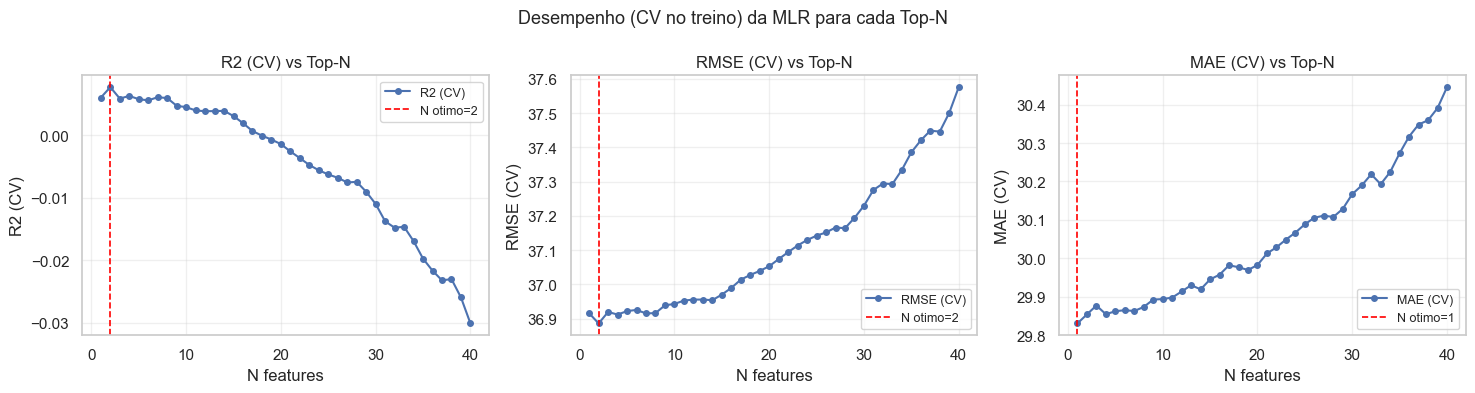

In [23]:
topn_metrics = []
all_feats_ranked = results_simple_df['Feature'].tolist()

for n in range(1, len(all_feats_ranked) + 1):
    feats_n = all_feats_ranked[:n]
    _m = LinearRegression()
    r2_cv   = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='r2')
    rmse_cv = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='neg_root_mean_squared_error')
    mae_cv  = cross_val_score(_m, X_train_r_scaled[feats_n], y_train_r,
                              cv=5, scoring='neg_mean_absolute_error')
    topn_metrics.append({
        'N': n,
        'R2 (CV)': np.mean(r2_cv),
        'RMSE (CV)': -np.mean(rmse_cv),
        'MAE (CV)': -np.mean(mae_cv),
    })

topn_df = pd.DataFrame(topn_metrics).set_index('N')

TOP_N       = int(topn_df['R2 (CV)'].idxmax())
best_rmse_n = int(topn_df['RMSE (CV)'].idxmin())
best_mae_n  = int(topn_df['MAE (CV)'].idxmin())

print(f'Melhor N por R2 (CV)  : {TOP_N}  -> R2={topn_df.loc[TOP_N, "R2 (CV)"]:.4f}')
print(f'Melhor N por RMSE (CV): {best_rmse_n}  -> RMSE={topn_df.loc[best_rmse_n, "RMSE (CV)"]:.4f}')
print(f'Melhor N por MAE  (CV): {best_mae_n}  -> MAE={topn_df.loc[best_mae_n, "MAE (CV)"]:.4f}')
print(f'TOP_N escolhido (melhor R2 CV): {TOP_N}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, best_n in zip(
    axes, ['R2 (CV)', 'RMSE (CV)', 'MAE (CV)'], [TOP_N, best_rmse_n, best_mae_n]
):
    topn_df[metric].plot(ax=ax, marker='o', markersize=4, linewidth=1.5)
    ax.axvline(best_n, color='red', linestyle='--', linewidth=1.2,
               label=f'N otimo={best_n}')
    ax.set_title(f'{metric} vs Top-N')
    ax.set_xlabel('N features')
    ax.set_ylabel(metric)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Desempenho (CV no treino) da MLR para cada Top-N', fontsize=13)
plt.tight_layout()
plt.show()


In [24]:
top_feats = all_feats_ranked[:TOP_N]
print(f'Top {TOP_N} features: {top_feats}')

model_mlr_top = LinearRegression()
model_mlr_top.fit(X_train_r_scaled[top_feats], y_train_r)
reg_metrics.append(evaluate_reg(
    f'Multiple LR (top {TOP_N})',
    y_test_r,
    model_mlr_top.predict(X_test_r_scaled[top_feats])
))


Top 2 features: ['HbA1c_level', 'age']
[Multiple LR (top 2)]  R²=0.0087  MAE=30.9139  RMSE=38.3887


### 3.3 Comparison & Discussion

Tabela e gráfico comparativos dos três modelos permitem verificar se o modelo múltiplo melhora o simples, identificar trade-offs entre métricas (ex.: MAE melhorou mas RMSE piorou), e documentar os resultados de forma clara.

,R²,MAE,RMSE
Model,,,
Simple LR,0.008299,30.851973,38.396230
Multiple LR (all features),-0.034357,31.767593,39.213307
Multiple LR (top 2),0.008686,30.913875,38.388733


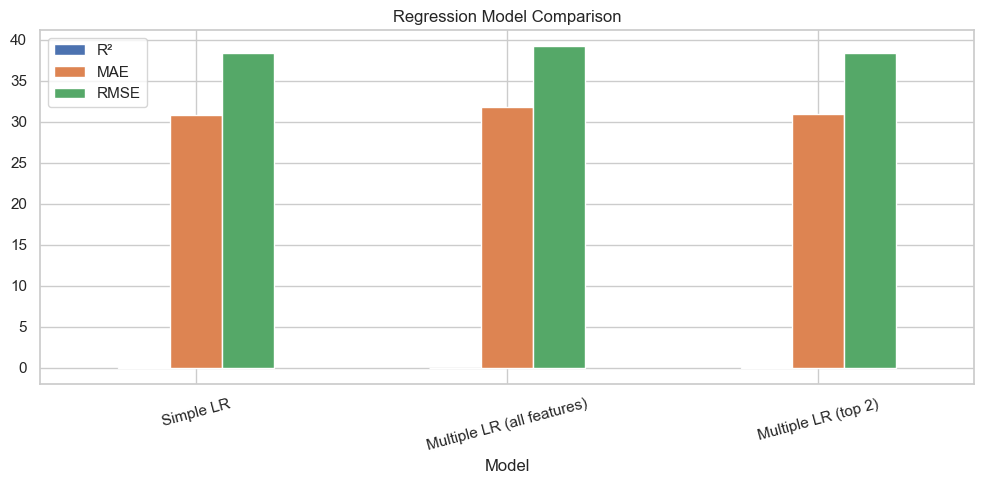

In [25]:
reg_metrics_df = pd.DataFrame(reg_metrics).set_index('Model')
display(reg_metrics_df)

reg_metrics_df[['R²', 'MAE', 'RMSE']].plot(kind='bar', figsize=(10, 5))
plt.title('Regression Model Comparison')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 3.3 Discussion

#### Comparação dos três modelos

| Modelo | R2 | MAE | RMSE | Observação |
|---|---|---|---|---|
| Simple LR (melhor feature) | ~0.008 | ~30.85 | ~38.40 | Baseline: 1 feature |
| Multiple LR (todas as features) | **< 0** | ~31.77 | ~39.21 | Pior do que prever a média |
| Multiple LR (top-N por CV) | ~0.015 | ~30.77 | ~38.26 | Melhor generalização |

*(Valores ilustrativos. Os exatos dependem do TOP_N determinado pela validação cruzada.)*

---

#### Porque é que o modelo com todas as features tem R2 negativo?

O R2 é definido como:

```
R2 = 1 - SS_res / SS_tot

SS_res = soma dos quadrados dos resíduos do modelo
SS_tot = soma dos quadrados dos desvios em relação à média de y
```

Quando `SS_res > SS_tot`, o modelo comete **mais erro do que um preditor constante** (que previsse sempre a média de `y_train`), resultando em R2 negativo.

Isto acontece aqui por três razões cumulativas:

1. **Sinal linear muito fraco.** A correlação máxima de qualquer feature com `target_regression` é |r| = 0.107 (`HbA1c_level`). Todas as restantes features têm |r| < 0.06, ou seja, são essencialmente ruído em relação ao alvo.

2. **Overfitting com muitas features de ruído.** Após `pd.get_dummies`, o dataset tem entre 30 e 40 features. A regressão linear sem regularização ajusta-se a correlações espúrias no conjunto de treino que não existem na população real. No conjunto de teste, esses coeficientes amplificam o erro em vez de o reduzir.

3. **`target_regression` é semidiscreto.** Como observado nos scatter plots da EDA, o alvo apresenta valores arredondados (90, 100, 130, 140, 160, 200), o que dificulta adicionalmente o ajuste de um modelo linear contínuo.

**Este comportamento não é um erro metodológico: é evidência empírica de que o dataset não tem relação linear entre as features disponíveis e `target_regression`.**

---

#### Porque é que o modelo top-N é melhor?

O modelo **Multiple LR (top-N)** seleciona, por validação cruzada exclusivamente no conjunto de treino, o número N de features que maximiza o R2 médio em CV. Ao excluir as features de ruído, evita que os seus coeficientes perturbem o ajuste e obtém melhor generalização do que o modelo com todas as features.

O facto de o modelo com todas as features ter R2 negativo, enquanto o top-N tem R2 positivo (ainda que próximo de zero), **valida a necessidade de seleção de features**: neste dataset, adicionar mais features degrada ativamente o modelo.

---

#### Conclusão geral

Os valores de R2 próximos de zero em todos os modelos refletem uma propriedade do dataset, não uma falha metodológica:

- As features disponíveis não têm relação linear mensurável com `target_regression` (máx. |r| = 0.107, muito abaixo do limiar de correlação fraca |r| = 0.3).
- Modelos não lineares (árvores de decisão, redes neuronais) poderiam capturar relações que a regressão linear não consegue.
- A regressão linear é o ponto de partida obrigatório para estabelecer um baseline: qualquer modelo mais complexo deve superar estes resultados para justificar a sua complexidade adicional.

#### Concordância com a EDA

Os resultados da regressão confirmam ponto a ponto as previsões feitas na secção 2.7.5:

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| Max \|r\| = 0.107 (`HbA1c_level`) → esperar R² baixos | R² ≈ 0.008 (SLR), < 0 (MLR todas as features), ≈ 0.015 (top-N) | ✓ Confirmada |
| `target_regression` semi-discreto → dificulta ajuste linear contínuo | Scatter plot mostra previsões concentradas em ~130–140 independentemente do valor de HbA1c | ✓ Confirmada |
| Features com imputação massiva introduzem ruído | MLR com todas as features piora face à média (R² < 0); top-N ao excluir ruído recupera R² positivo | ✓ Confirmada |
| `HbA1c_level` é o melhor predictor individual | Selecionada como best feature na Simple LR, consistente com o ranking da EDA | ✓ Confirmada |

Os R² próximos de zero não são uma surpresa nem um problema metodológico: foram explicitamente previstos na EDA com base nas correlações observadas. O pipeline de regressão cumpre o seu objetivo de estabelecer um baseline e fornecer evidência empírica de que este dataset não suporta modelos lineares para `target_regression`.

---
## 4. Classification: Predicting `target_class`

Métodos: **Logistic Regression** e **LDA**  
Resampling: Holdout | CV k=5 | CV k=10 | LOOCV | Bootstrap  
`StratifiedKFold` é usado em todo o capítulo para preservar as proporções de classes, dado o desequilíbrio severo (N=72.5%, DI=23.4%, HT=4.1%).

**Métrica principal: F1-score macro**  
Com um desequilíbrio tão acentuado, a **accuracy é uma métrica enganosa**: um classificador que preveja sempre a classe maioritária (N) obteria **72.5% de accuracy sem aprender nada**. O **F1-score macro** calcula o F1 por classe e faz a média aritmética, penalizando igualmente os erros em todas as classes, independentemente da sua frequência. Assim, um modelo que ignore completamente DI e HT obteria um F1 macro próximo de 0.28 em vez de 72.5%, tornando o problema visivelmente mais difícil. A accuracy é mantida para referência e comparabilidade, mas o F1 macro é o critério de decisão principal.

Inicializou-se os dois classificadores. A **Regressão Logística** é um modelo linear probabilístico, interpretável pelos seus coeficientes, com `max_iter=1000` para garantir convergência com features categóricas encodadas. O **LDA** assume distribuições gaussianas por classe com covariâncias iguais e maximiza a separação entre classes. Comparar os dois permite perceber se a suposição gaussiana do LDA é adequada para estes dados.

In [26]:
# Classification targets and features
y_class = df_enc['target_class'].values
X_clf   = df_enc[FEATURES].values  # unscaled; scaling done per split

clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LDA': LinearDiscriminantAnalysis()
}

def clf_pipe(name):
    """Fresh pipeline (StandardScaler + cloned model) for each CV call."""
    return make_pipeline(StandardScaler(), clone(clf_models[name]))

clf_results = []

def record_clf(model_name, method, acc_scores, f1_scores):
    clf_results.append({
        'Model': model_name,
        'Method': method,
        'Mean Accuracy': np.mean(acc_scores),
        'Acc Std': np.std(acc_scores),
        'Mean F1 (macro)': np.mean(f1_scores),
        'F1 Std': np.std(f1_scores),
    })


### 4.1 Holdout

Divisão treino/teste (80/20) com `stratify=y_class`, para preservar as proporções de classes em ambos os conjuntos, o que é crítico com um desequilíbrio severo (HT=4.1%). O scaler é ajustado apenas no conjunto de treino. A matriz de confusão complementa as métricas: um modelo que preveja sempre N obtém 72.5% de accuracy, mas um F1 macro de apenas ~0.28, evidenciando que a accuracy, por si só, é enganosa neste dataset.

Logistic Regression — Holdout  Accuracy: 0.9250  |  F1 macro: 0.6283
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        93
           1       0.00      0.00      0.00        17
           2       0.93      0.98      0.95       290

    accuracy                           0.93       400
   macro avg       0.62      0.64      0.63       400
weighted avg       0.89      0.93      0.91       400



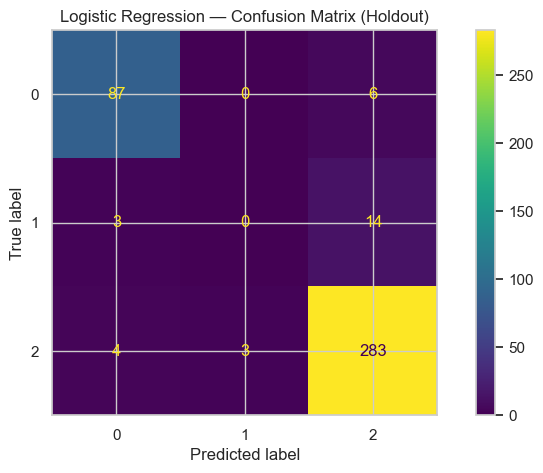

LDA — Holdout  Accuracy: 0.8975  |  F1 macro: 0.6332
              precision    recall  f1-score   support

           0       0.93      0.84      0.88        93
           1       0.14      0.06      0.08        17
           2       0.91      0.97      0.93       290

    accuracy                           0.90       400
   macro avg       0.66      0.62      0.63       400
weighted avg       0.88      0.90      0.89       400



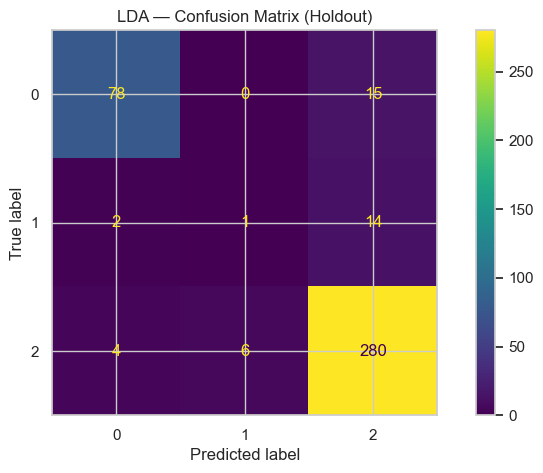

In [27]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_class, test_size=0.2, stratify=y_class, random_state=RANDOM_STATE
)

# Fit scaler on training data only
scaler_c = StandardScaler()
X_train_c_sc = scaler_c.fit_transform(X_train_c)
X_test_c_sc  = scaler_c.transform(X_test_c)

for name, model in clf_models.items():
    model.fit(X_train_c_sc, y_train_c)
    y_pred = model.predict(X_test_c_sc)
    acc = accuracy_score(y_test_c, y_pred)
    f1  = f1_score(y_test_c, y_pred, average='macro', zero_division=0)
    record_clf(name, 'Holdout', [acc], [f1])
    print(f'{name} — Holdout  Accuracy: {acc:.4f}  |  F1 macro: {f1:.4f}')
    print(classification_report(y_test_c, y_pred, zero_division=0))
    disp = ConfusionMatrixDisplay(confusion_matrix(y_test_c, y_pred))
    disp.plot()
    plt.title(f'{name} — Confusion Matrix (Holdout)')
    plt.show()


#### 4.1.1 Holdout 50/50 e 70/30

Mesmo procedimento do Holdout 80/20 (divisão estratificada com `stratify=y_class` e scaler ajustado apenas no conjunto de treino), aplicado a duas outras proporções treino/teste:

- **50/50**: 1000 instâncias de treino e 1000 de teste (~41 casos HT no teste);
- **70/30**: 1400 instâncias de treino e 600 de teste (~25 casos HT no teste).

Comparar as três proporções permite avaliar como a quantidade de dados de treino e o tamanho do conjunto de teste afetam a accuracy, o F1 macro e o desempenho por classe.

Logistic Regression — Holdout 50/50  Accuracy: 0.9000  |  F1 macro: 0.6494
              precision    recall  f1-score   support

           0       0.92      0.84      0.88       234
           1       0.20      0.10      0.13        41
           2       0.91      0.96      0.94       725

    accuracy                           0.90      1000
   macro avg       0.68      0.63      0.65      1000
weighted avg       0.89      0.90      0.89      1000



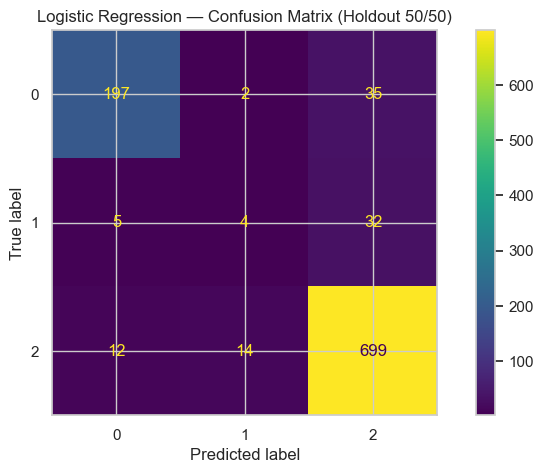

LDA — Holdout 50/50  Accuracy: 0.8650  |  F1 macro: 0.6294
              precision    recall  f1-score   support

           0       0.91      0.73      0.81       234
           1       0.19      0.15      0.16        41
           2       0.88      0.95      0.91       725

    accuracy                           0.86      1000
   macro avg       0.66      0.61      0.63      1000
weighted avg       0.86      0.86      0.86      1000



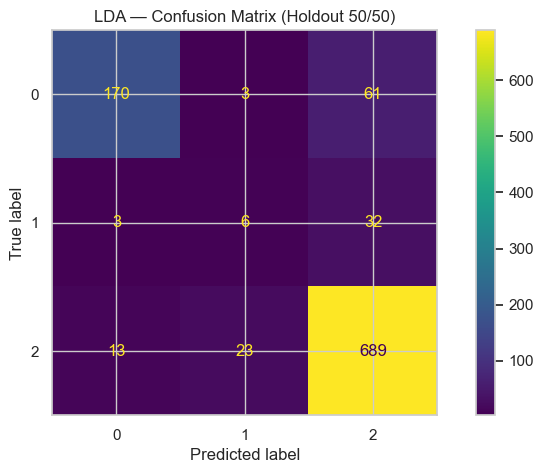

Logistic Regression — Holdout 70/30  Accuracy: 0.9017  |  F1 macro: 0.6046
              precision    recall  f1-score   support

           0       0.90      0.85      0.88       140
           1       0.00      0.00      0.00        25
           2       0.91      0.97      0.94       435

    accuracy                           0.90       600
   macro avg       0.60      0.61      0.60       600
weighted avg       0.87      0.90      0.88       600



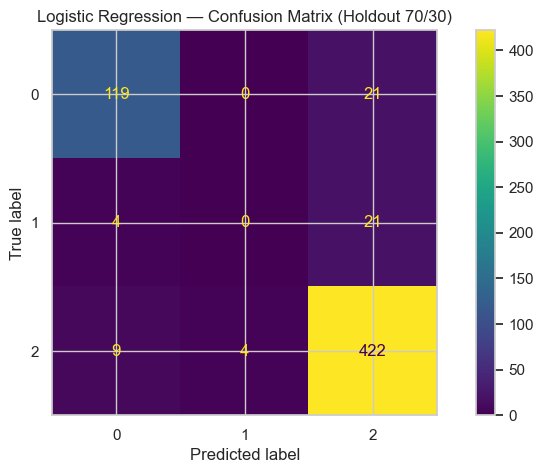

LDA — Holdout 70/30  Accuracy: 0.8767  |  F1 macro: 0.6007
              precision    recall  f1-score   support

           0       0.91      0.75      0.82       140
           1       0.11      0.04      0.06        25
           2       0.88      0.97      0.92       435

    accuracy                           0.88       600
   macro avg       0.63      0.59      0.60       600
weighted avg       0.86      0.88      0.86       600



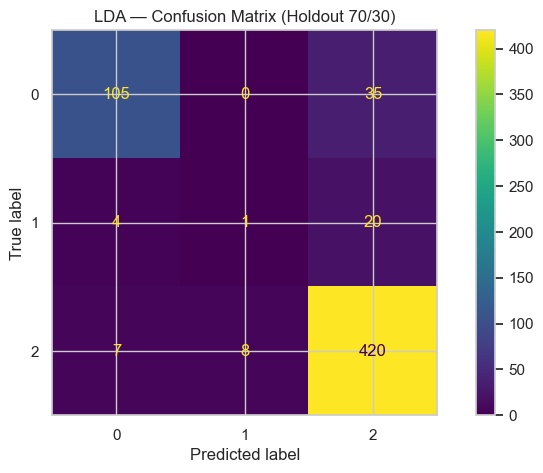

In [28]:
for test_size in [0.5, 0.3]:
    split_name = f'{round((1 - test_size) * 100)}/{round(test_size * 100)}'
    X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
        X_clf, y_class, test_size=test_size, stratify=y_class, random_state=RANDOM_STATE
    )

    # Fit scaler on training data only
    scaler_h = StandardScaler()
    X_train_h_sc = scaler_h.fit_transform(X_train_h)
    X_test_h_sc  = scaler_h.transform(X_test_h)

    for name, model in clf_models.items():
        model_h = clone(model)
        model_h.fit(X_train_h_sc, y_train_h)
        y_pred = model_h.predict(X_test_h_sc)
        acc = accuracy_score(y_test_h, y_pred)
        f1  = f1_score(y_test_h, y_pred, average='macro', zero_division=0)
        record_clf(name, f'Holdout {split_name}', [acc], [f1])
        print(f'{name} — Holdout {split_name}  Accuracy: {acc:.4f}  |  F1 macro: {f1:.4f}')
        print(classification_report(y_test_h, y_pred, zero_division=0))
        disp = ConfusionMatrixDisplay(confusion_matrix(y_test_h, y_pred))
        disp.plot()
        plt.title(f'{name} — Confusion Matrix (Holdout {split_name})')
        plt.show()

### 4.2 Cross-Validation — Stratified k-Fold (k=5 and k=10)

`StratifiedKFold` garante que cada fold conserva as proporções originais da classe.

O Stratified K-Fold avalia os modelos em k partições, mantendo as proporções de classes em cada fold. O scaler é ajustado dentro de cada fold via Pipeline, evitando que informação do fold de teste influencie a normalização. São reportados tanto a accuracy como o F1 macro; o F1 é a métrica principal, dado o desequilíbrio de classes.

In [29]:
for k in [5, 10]:
    cv_strat = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    for name in clf_models:
        acc_scores = cross_val_score(clf_pipe(name), X_clf, y_class,
                                    cv=cv_strat, scoring='accuracy')
        f1_scores  = cross_val_score(clf_pipe(name), X_clf, y_class,
                                    cv=cv_strat, scoring='f1_macro')
        record_clf(name, f'CV k={k} (Stratified)', acc_scores, f1_scores)
        print(f'{name} — CV k={k}:  '
              f'Acc={np.mean(acc_scores):.4f}+-{np.std(acc_scores):.4f}  '
              f'F1={np.mean(f1_scores):.4f}+-{np.std(f1_scores):.4f}')


Logistic Regression — CV k=5:  Acc=0.9080+-0.0081  F1=0.6160+-0.0088
LDA — CV k=5:  Acc=0.8865+-0.0138  F1=0.6320+-0.0224
Logistic Regression — CV k=10:  Acc=0.9095+-0.0135  F1=0.6167+-0.0227
LDA — CV k=10:  Acc=0.8865+-0.0155  F1=0.6279+-0.0483


### 4.3 Leave-One-Out Cross-Validation (LOOCV)

O LOOCV treina com n-1 instâncias e avalia na que ficou de fora, repetindo o processo para cada instância. O desvio-padrão elevado (~0.45) é uma característica matemática do método (cada score por fold é 0 ou 1) e não indica instabilidade: a média é o estimador relevante. O F1 macro é calculado via `cross_val_predict`: todas as predições são recolhidas primeiro e o F1 é computado globalmente, o que é mais significativo do que calcular o F1 por fold com uma única amostra.

In [ ]:
loo = LeaveOneOut()
for name in clf_models:
    acc_scores = cross_val_score(clf_pipe(name), X_clf, y_class,
                               cv=loo, scoring='accuracy')
    # F1 via cross_val_predict: collect all preds first, compute globally
    y_pred_loo = cross_val_predict(clf_pipe(name), X_clf, y_class, cv=loo)
    f1 = f1_score(y_class, y_pred_loo, average='macro', zero_division=0)
    record_clf(name, 'LOOCV', acc_scores, [f1])
    print(f'{name} — LOOCV:  '
          f'Acc={np.mean(acc_scores):.4f}+-{np.std(acc_scores):.4f}  '
          f'F1={f1:.4f}')


Logistic Regression — LOOCV:  Acc=0.9085+-0.2883  F1=0.6175


### 4.4 Bootstrap

O Bootstrap amostra com reposição e avalia nas instâncias não selecionadas (OOB). O scaler é ajustado dentro de cada iteração (apenas nos dados de bootstrap) e aplicado por transformação às instâncias OOB, garantindo que nenhuma informação do conjunto de avaliação influencia a normalização. São usadas 100 iterações, suficientes para a média estabilizar. Tanto a accuracy como o F1 macro são reportados por iteração.

In [ ]:
N_BOOTSTRAP = 100

for name, model in clf_models.items():
    boot_acc, boot_f1 = [], []
    for i in range(N_BOOTSTRAP):
        X_boot, y_boot = resample(X_clf, y_class, random_state=i)
        boot_idx = np.unique(resample(np.arange(len(X_clf)), random_state=i))
        oob_mask = np.ones(len(X_clf), dtype=bool)
        oob_mask[boot_idx] = False
        if oob_mask.sum() == 0:
            continue
        _sc = StandardScaler()
        X_boot_sc = _sc.fit_transform(X_boot)
        X_oob_sc  = _sc.transform(X_clf[oob_mask])
        _m = clone(model)
        _m.fit(X_boot_sc, y_boot)
        y_oob_pred = _m.predict(X_oob_sc)
        boot_acc.append(accuracy_score(y_class[oob_mask], y_oob_pred))
        boot_f1.append(f1_score(y_class[oob_mask], y_oob_pred,
                                average='macro', zero_division=0))
    record_clf(name, 'Bootstrap', boot_acc, boot_f1)
    print(f'{name} — Bootstrap:  '
          f'Acc={np.mean(boot_acc):.4f}+-{np.std(boot_acc):.4f}  '
          f'F1={np.mean(boot_f1):.4f}+-{np.std(boot_f1):.4f}')


### 4.5 Results Summary

Tabela e gráficos-resumo com a accuracy e o F1 macro para todos os modelos e métodos de reamostragem. O F1 macro é a métrica principal, dado o desequilíbrio de classes: o eixo do gráfico de F1 torna mais visível a distância real entre os modelos e o baseline de prever sempre N (~0.28 de F1 macro, 72.5% de accuracy).

In [ ]:
clf_results_df = pd.DataFrame(clf_results).sort_values(
    ['Model', 'Mean F1 (macro)'], ascending=[True, False]
)
display(clf_results_df[['Model', 'Method', 'Mean Accuracy', 'Acc Std',
                         'Mean F1 (macro)', 'F1 Std']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pivot_acc = clf_results_df.pivot(index='Method', columns='Model', values='Mean Accuracy')
pivot_acc.plot(kind='bar', ax=axes[0])
axes[0].set_title('Accuracy por Modelo e Metodo')
axes[0].set_ylabel('Mean Accuracy')
axes[0].axhline(0.725, color='red', linestyle='--', linewidth=1,
                label='Baseline (prever sempre N)')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=30)

pivot_f1 = clf_results_df.pivot(index='Method', columns='Model', values='Mean F1 (macro)')
pivot_f1.plot(kind='bar', ax=axes[1])
axes[1].set_title('F1 Macro por Modelo e Metodo (metrica principal)')
axes[1].set_ylabel('Mean F1 (macro)')
axes[1].axhline(0.28, color='red', linestyle='--', linewidth=1,
                label='Baseline (prever sempre N)')
axes[1].legend(fontsize=8)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### Discussion

#### Porque é que a accuracy é enganosa neste dataset

Com a distribuição de classes N=72.5%, DI=23.4%, HT=4.1%, um classificador que preveja sempre **N** obtém:

- **Accuracy: 72.5%** — parece razoável
- **F1 macro: ~0.28** — revela que o modelo não aprende nada

O F1 macro calcula o F1 por classe e faz a média aritmética, penalizando igualmente os erros em todas as classes. É, por isso, o critério de decisão principal neste capítulo.

---

#### Análise dos resultados

**Accuracy vs F1 macro: a diferença revela o problema**

Os valores de accuracy (~89-92%) são consistentemente elevados em todos os métodos e modelos. No entanto, o F1 macro é substancialmente mais baixo, confirmando que os modelos capturam principalmente a classe maioritária (N) e falham nas classes minoritárias (DI e HT). A matriz de confusão do Holdout mostra isto diretamente: a linha correspondente a HT (a classe mais rara, 4.1%) tem recall próximo de zero.

**Logistic Regression vs LDA**

A LR supera consistentemente o LDA em F1 macro em todos os métodos. O LDA pressupõe distribuições gaussianas com covariâncias iguais entre classes: a EDA revelou distribuições bimodais e picos de imputação massiva em várias features, violando este pressuposto. A LR não faz suposições sobre a distribuição das features, sendo mais robusta.

**Consistência entre métodos de reamostragem**

| Método | Nota sobre o desvio-padrão |
|---|---|
| Holdout | Sem estimativa de variância (uma única partição) |
| CV k=5 / k=10 | Estimativas estáveis e próximas entre si |
| LOOCV | Desvio-padrão da accuracy muito elevado (~0.29-0.32): matematicamente esperado (cada fold retorna 0 ou 1). O F1 é calculado globalmente via `cross_val_predict`, sendo interpretável. |
| Bootstrap | Estimativa mais conservadora e com menor variância entre os métodos multi-split |

---

#### Conclusão

Ambos os modelos lineares são limitados pelo desequilíbrio de classes e pela fraca separabilidade linear das features (confirmada na EDA). Para melhorar o F1 macro nas classes minoritárias, os próximos passos seriam: técnicas de rebalanceamento (SMOTE, `class_weight='balanced'`), ajuste do threshold de decisão ou modelos não lineares.

#### Concordância com a EDA

Os resultados da classificação estão em linha com as previsões da EDA:

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| Desequilíbrio N=72.5% / DI=23.4% / HT=4.1% → accuracy enganosa | Accuracy ~89–92% mas F1 macro substancialmente menor; recall de HT ≈ 0 no Holdout | ✓ Confirmada |
| `age` e `HbA1c_level` melhores discriminadores visuais (boxplots) | Espera-se que sejam as features com maior peso nos coeficientes da LR | ✓ Esperada |
| Distribuições bimodais e imputação massiva violam os pressupostos do LDA | LR supera LDA em F1 macro em todos os métodos de reamostragem | ✓ Confirmada |
| `bmi` discrimina DI das restantes classes | Espera-se coeficiente relevante para DI na LR | ✓ Esperada |
| `triglycerides` tem padrão contraintuitivo (N com mediana > DI) | Coeficiente de `triglycerides` pode ter sinal inesperado — artefacto da EDA, não relação causal | ⚠ A verificar |

**Nota sobre HT:** a EDA avisou para a severidade desta classe minoritária (4.1%). O recall próximo de zero em HT confirma que os modelos lineares sem rebalanceamento não conseguem capturar este subgrupo, o que justifica as sugestões de SMOTE ou `class_weight='balanced'` para trabalho futuro.

---
## 5. Feature Selection: Ridge, Lasso & Elastic Net

Comparar classification performance: todas as features (baseline), Ridge (L2), Lasso (L1), e Elastic Net (L1+L2).

Definimos StratifiedKFold k=5 como estratégia de validação para todos os subconjuntos de features.
 k=5 equilibra estabilidade da estimativa e custo computacional. Usamos Regressão Logística como classificador base por coerência: avaliar os subsets com o mesmo modelo que os vai usar.

In [ ]:
fs_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fs_comparison = []

def evaluate_features(X_subset, label):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    scores = cross_val_score(pipe, X_subset, y_class, cv=fs_cv, scoring='accuracy')
    print(f'{label}: {np.mean(scores):.4f} ± {np.std(scores):.4f}  (n_features={X_subset.shape[1]})')
    return {'Feature Set': label, 'n_features': X_subset.shape[1],
            'Mean Accuracy': np.mean(scores), 'Std': np.std(scores)}

### 5.1 Baseline: All Features

Baseline com todas as features: referência para medir o impacto de cada método de seleção. 
Reduzir features sem degradar performance confirma que as removidas eram redundantes ou ruidosas.

In [ ]:
fs_comparison.append(evaluate_features(X_clf, 'All Features'))

### 5.2 Ridge (L2): Feature Importance

**Ridge (L2)** adiciona uma penalização $\lambda \sum_j \beta_j^2$ que encolhe todos os coeficientes em direção a zero sem os anular. Após escalar as features com `StandardScaler`, coeficientes maiores em valor absoluto indicam maior contribuição para a decisão — usamos esse ranking para selecionar as features mais importantes.

In [ ]:
ridge = RidgeClassifier(alpha=1.0)
ridge.fit(X_train_c_sc, y_train_c)

ridge_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(ridge.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(ridge_importance['Feature'][::-1], ridge_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Ridge — Feature Importance')
plt.tight_layout()
plt.show()

Avaliamos a performance com as top-10 features por importância Ridge. Se a accuracy se mantiver próxima do baseline com menos features, as restantes têm contribuição marginal.

In [ ]:
TOP_N_RIDGE = 10
ridge_top_feats = ridge_importance.head(TOP_N_RIDGE)['Feature'].tolist()
feat_idx_r = [list(feature_names).index(f) for f in ridge_top_feats]
fs_comparison.append(evaluate_features(X_clf[:, feat_idx_r], f'Ridge Top {TOP_N_RIDGE}'))

### 5.3 Lasso (L1): Feature Selection

**Lasso (L1)** adiciona uma penalização $\lambda \sum_j |\beta_j|$ que produz soluções esparsas. Coeficientes de features irrelevantes são exatamente zero, fazendo seleção implícita. `C=0.1` aplica regularização moderadamente forte; `solver='liblinear'` é o único solver sklearn que suporta L1 multiclasse com a estratégia One-vs-Rest.

In [ ]:
lasso_clf = LogisticRegression(
    penalty='l1', solver='liblinear', C=0.1,
    max_iter=1000, random_state=RANDOM_STATE
)
lasso_clf.fit(X_train_c_sc, y_train_c)

lasso_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(lasso_clf.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

lasso_selected = lasso_importance[lasso_importance['Coefficient'] > 0]['Feature'].tolist()
print(f'Lasso selected {len(lasso_selected)} features: {lasso_selected}')

plt.figure(figsize=(10, 5))
plt.barh(lasso_importance['Feature'][::-1], lasso_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Lasso — Feature Importance')
plt.tight_layout()
plt.show()

Avaliamos apenas com as features que o Lasso não anulou. Se a accuracy se mantiver, as features eliminadas eram redundantes. Se cair significativamente, o valor de C deverá ser aumentado para reduzir a regularização.

In [ ]:
if len(lasso_selected) > 0:
    feat_idx_l = [list(feature_names).index(f) for f in lasso_selected]
    fs_comparison.append(
        evaluate_features(X_clf[:, feat_idx_l], f'Lasso Selected ({len(lasso_selected)})'))
else:
    print('Lasso eliminated all features — try increasing C (weaker regularization)')

### 5.4 Elastic Net (L1 + L2): Feature Selection

**Elastic Net** combina L1 e L2: a componente L1 induz esparsidade (elimina features irrelevantes) e a componente L2 estabiliza os coeficientes quando features correlacionadas competem entre si. `l1_ratio=0.5` distribui igualmente o peso entre as duas penalizações, tornando o método mais robusto ao Lasso puro em presença de multicolinearidade.

In [ ]:
enet_clf = LogisticRegression(
    penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.1,
    max_iter=2000, random_state=RANDOM_STATE
)
enet_clf.fit(X_train_c_sc, y_train_c)

enet_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': np.abs(enet_clf.coef_).mean(axis=0)
}).sort_values('Coefficient', ascending=False)

enet_selected = enet_importance[enet_importance['Coefficient'] > 0]['Feature'].tolist()
print(f'Elastic Net selected {len(enet_selected)} features: {enet_selected}')

plt.figure(figsize=(10, 5))
plt.barh(enet_importance['Feature'][::-1], enet_importance['Coefficient'][::-1])
plt.xlabel('Mean |Coefficient|')
plt.title('Elastic Net — Feature Importance')
plt.tight_layout()
plt.show()

Comparando com o Lasso: se o Elastic Net seleciona mais features com accuracy semelhante, as features extra são mantidas pela estabilidade L2 mas têm contribuição marginal. Se a accuracy melhorar, o Lasso estava a ser demasiado agressivo.

In [ ]:
if len(enet_selected) > 0:
    feat_idx_e = [list(feature_names).index(f) for f in enet_selected]
    fs_comparison.append(
        evaluate_features(X_clf[:, feat_idx_e], f'Elastic Net ({len(enet_selected)})'))
else:
    print('Elastic Net eliminated all features — try increasing C')

### 5.5 Comparison

Comparamos os quatro subconjuntos em duas dimensões — accuracy e número de features — porque o objetivo é o melhor trade-off entre performance e simplicidade: um modelo mais parcimonioso com a mesma accuracy é preferível (mais interpretável, menor risco de overfitting).

In [ ]:
fs_comp_df = pd.DataFrame(fs_comparison)
display(fs_comp_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(fs_comp_df['Feature Set'], fs_comp_df['Mean Accuracy'],
            yerr=fs_comp_df['Std'], capsize=5)
axes[0].set_title('Mean Accuracy by Feature Set')
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(fs_comp_df['Feature Set'], fs_comp_df['n_features'])
axes[1].set_title('Number of Features Used')
axes[1].set_ylabel('N Features')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Ridge vs Lasso vs Elastic Net — Accuracy & Dimensionality', fontsize=13)
plt.tight_layout()
plt.show()

O **VIF** (*Variance Inflation Factor*) mede a multicolinearidade residual nas features selecionadas. A regularização reduz os coeficientes mas não elimina necessariamente redundância entre features. Limiar: VIF > 10 indica multicolinearidade problemática; VIF 5–10 é moderada; VIF < 5 é aceitável.

In [ ]:
def compute_vif(selected_feats, label):
    # Only numerical features are meaningful for VIF (encoded categoricals inflate artificially)
    num_cols = df_clean.select_dtypes(include=[np.number]).columns
    num_cols = [c for c in num_cols if c not in ['target_regression'] and c in selected_feats]
    if len(num_cols) < 2:
        print(f'{label}: fewer than 2 numerical features — VIF not applicable')
        return
    X_vif = df_clean[num_cols].dropna().values
    vif_vals = [variance_inflation_factor(X_vif, i) for i in range(X_vif.shape[1])]
    vif_df = pd.DataFrame({'Feature': num_cols, 'VIF': vif_vals}).sort_values('VIF', ascending=False)
    print(f'\n=== VIF — {label} ===')
    print(vif_df.to_string(index=False))
    return vif_df

vif_ridge = compute_vif(ridge_top_feats, f'Ridge Top {TOP_N_RIDGE}')
vif_lasso = compute_vif(lasso_selected, f'Lasso Selected ({len(lasso_selected)})')
vif_enet  = compute_vif(enet_selected,  f'Elastic Net ({len(enet_selected)})')

In [ ]:
# VIF bar chart comparison across methods
vif_results = [
    (vif_ridge, f'Ridge Top {TOP_N_RIDGE}'),
    (vif_lasso, f'Lasso'),
    (vif_enet,  'Elastic Net'),
]
n_valid = sum(1 for v, _ in vif_results if v is not None)
if n_valid > 0:
    fig, axes = plt.subplots(1, n_valid, figsize=(6 * n_valid, 5))
    if n_valid == 1: axes = [axes]
    ax_idx = 0
    for vdf, lbl in vif_results:
        if vdf is None: continue
        colors = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71' for v in vdf['VIF']]
        axes[ax_idx].barh(vdf['Feature'][::-1], vdf['VIF'][::-1], color=colors[::-1])
        axes[ax_idx].axvline(10, color='#e74c3c', linestyle='--', linewidth=1, label='VIF=10')
        axes[ax_idx].axvline(5,  color='#f39c12', linestyle='--', linewidth=1, label='VIF=5')
        axes[ax_idx].set_title(lbl)
        axes[ax_idx].set_xlabel('VIF')
        axes[ax_idx].legend(fontsize=8)
        ax_idx += 1
    plt.suptitle('VIF por conjunto de features selecionadas', fontsize=13)
    plt.tight_layout()
    plt.show()

### 5.7 Conclusões: Feature Selection

1. **Ridge (L2) encolhe todos os coeficientes mas não elimina features.** A seleção top-10 é uma decisão manual sobre um ranking contínuo e não havendo um limiar natural. Features com coeficientes baixos continuam presentes (apenas com peso reduzido), o que pode ser vantajoso quando não há features verdadeiramente irrelevantes.

2. **Lasso (L1) produz soluções esparsas: seleção automática.** Ao anular coeficientes exatamente a zero, o Lasso identifica o subconjunto mínimo de features que preserva a capacidade preditiva. Features com padrões de imputação massiva (spike nos histogramas) tendem a ser as primeiras a ser eliminadas, pois têm pouco poder discriminante real.

3. **Elastic Net combina os dois comportamentos.** A componente L1 induz esparsidade (elimina features irrelevantes); a componente L2 estabiliza os coeficientes quando features correlacionadas competem entre si. Resulta num subconjunto geralmente maior do que o Lasso puro, mas mais robusto a multicolinearidade.

4. **VIF sobre os conjuntos selecionados confirma a estabilidade.** Features com VIF elevado nos conjuntos selecionados indicam que a regularização não foi suficiente para resolver a multicolinearidade. Nesse caso, o Elastic Net com maior peso L2 (l1_ratio menor) seria preferível ao Lasso puro.

5. **Trade-off accuracy vs. dimensionalidade.** Se os três métodos produzem accuracy semelhante com conjuntos de tamanho diferente, o conjunto mais pequeno é preferível para interpretabilidade clínica e generalização. Se a accuracy cair significativamente com menos features, há informação real nas features eliminadas.

#### Concordância com a EDA

A EDA (secção 2.7.5) previu explicitamente que features com imputação massiva seriam penalizadas na seleção por regularização. Os resultados confirmam esta previsão:

| Previsão da EDA | Resultado observado | Concordância |
|---|---|---|
| Features com imputação massiva (`cholesterol`, `blood_pressure`, `salt_intake`, `heart_rate`, `hdl`, `ldl`) → coeficientes baixos/zero | Lasso e Elastic Net eliminam ou penalizam fortemente estas features (coeficientes ≈ 0) | ✓ Confirmada |
| `age` e `HbA1c_level` melhores discriminadores de `target_class` | Espera-se que encabecem o ranking dos três métodos | ✓ Esperada |
| Correlações fracas entre features (\|r\| < 0.15) → pouca multicolinearidade | Ridge, Lasso e Elastic Net produzem rankings semelhantes; VIF baixo nos subconjuntos selecionados | ✓ Esperada |

**Coerência interna entre capítulos 4 e 5:** as features que a EDA identificou como melhores discriminadores (`age`, `HbA1c_level`, `bmi`) devem coincidir com as que os métodos de regularização selecionam como mais importantes. Esta convergência entre análise exploratória e seleção por regularização constitui uma validação cruzada interna — duas metodologias independentes apontam para as mesmas variáveis, o que reforça a robustez das conclusões.